# ABIDE I multimodal — Kaggle T4: ViT, DeiT, Swin × MLP, LightGBM

**Satu notebook dari unduhan sampai hasil akhir.** Di Kaggle: Import Notebook → pilih file ini
→ Settings: **Accelerator GPU T4** dan **Internet On** → Run All. Jika tersedia T4 ×2,
notebook memakai `cuda:0`; tidak memerlukan multi-GPU. Default `MODE="full"` menjalankan
seluruh cohort dan 5 fold. Gunakan `MODE="smoke"` untuk uji alur kecil dahulu.

Alur: unduh T1/CSV → audit dan cleaning → skull stripping SynthStrip → normalisasi otak
dan resampling 128³ → tiga tampilan anatomi 2.5D → fine-tuning tiga keluarga ViT → MLP
dan LightGBM pada fenotipik → concatenation fitur citra–fenotipik → evaluasi dan ablasi.

| Encoder citra | Model `timm` | Representasi untuk fusion |
|---|---|---|
| ViT-Tiny | `vit_tiny_patch16_224.augreg_in21k_ft_in1k` | 128 dimensi |
| DeiT-Tiny Distilled | `deit_tiny_distilled_patch16_224.fb_in1k` | 128 dimensi |
| Swin-Tiny | `swin_tiny_patch4_window7_224.ms_in1k` | 128 dimensi |

**Tabular hanya MLP dan LightGBM.** Ada 11 konfigurasi per fold: 3 citra-only, 2 tabular-only,
dan 6 fusion (3 encoder × 2 classifier). Seluruhnya memakai subjek dan split yang sama.
MLP dan LightGBM juga menerima concatenation fitur pada eksperimen fusion, sehingga
perbandingan kedua classifier memakai representasi citra yang sama.

Ini adaptasi flowchart ke **multi-view 2.5D**, bukan 3D ViT/Swin penuh. Tiap bidang sagital,
koronal, aksial memakai tiga slice sebagai kanal (9 slice/subjek), dengan input 224².
Skull stripping tetap dilakukan pada volume 3D. Tidak ada registrasi atlas otomatis;
inspeksi mask/QC tetap diperlukan. Bobot awal berasal dari ImageNet; ViT memakai pretraining
ImageNet-21k→1k, DeiT/Swin ImageNet-1k. Ukuran model dan sumber pretraining berbeda, sehingga
ini perbandingan pipeline transfer learning, bukan isolasi pengaruh arsitektur saja.

Hasil dan checkpoint disimpan di `/kaggle/working/abide_results`; raw/cache di
`/kaggle/temp/abide_*`. **Cache temp tidak menjadi output permanen.** Untuk sesi berikutnya,
lampirkan cache/hasil yang sudah disimpan sebagai Kaggle Dataset dan atur `CACHE_INPUT_ROOT`
serta `RESUME_INPUT_ROOT`; `INPUT_ROOT` digunakan untuk raw NIfTI/CSV. Checkpoint `last` memungkinkan lanjut pada batas epoch; `best` dipakai
untuk evaluasi. Waktu/VRAM sebenarnya dicatat, tanpa asumsi semua eksperimen selesai satu sesi.

## 1. Instalasi dependensi

Sel pertama mempertahankan PyTorch/torchvision bawaan Kaggle dan memasang paket aplikasi.
Tidak memasang ulang CUDA. Internet diperlukan untuk Drive, CSV dan bobot pretrained.

In [1]:
import os, sys, subprocess
INSTALL_DEPENDENCIES = os.getenv("ABIDE_INSTALL", "1") == "1"
if INSTALL_DEPENDENCIES:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
        "timm==1.0.22", "lightgbm==4.6.0", "gdown==6.1.0", "nibabel>=5.3,<6",
        "numpy>=1.26,<3", "pandas>=2.2,<3", "scipy>=1.12,<2",
        "scikit-learn>=1.5,<1.8", "matplotlib>=3.9,<3.11",
        "requests>=2.32,<3", "joblib>=1.3,<2", "tqdm>=4.66,<5"])
os.environ.setdefault("HF_HUB_DISABLE_XET", "1")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.1/63.1 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 43.8 MB/s eta 0:00:00


'false'

In [2]:
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
from contextlib import nullcontext
from importlib.metadata import version
import base64, gc, gzip, hashlib, json, math, random, re, shutil, time, zipfile
import joblib, gdown, requests
import nibabel as nib
from nibabel.processing import conform, resample_from_to
import numpy as np
import pandas as pd
from scipy import ndimage as ndi
import matplotlib.pyplot as plt
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset
import timm
from timm.data import resolve_model_data_config
import lightgbm as lgb
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay)
from threadpoolctl import threadpool_limits
from tqdm.auto import tqdm
from IPython.display import display, Markdown, FileLink

IS_KAGGLE = Path("/kaggle").exists()
MODE = os.getenv("ABIDE_MODE", "full")
CV_PROTOCOL = os.getenv("ABIDE_PROTOCOL", "stratified")  # alternatif: center_group
SEED, N_FOLDS = 42, 5
SMOKE_SUBJECTS = 10
CV_EPOCHS = int(os.getenv("ABIDE_CV_EPOCHS", "12" if MODE=="full" else "1"))
MLP_EPOCHS = int(os.getenv("ABIDE_MLP_EPOCHS", "80" if MODE=="full" else "2"))
LGB_ROUNDS = 700 if MODE=="full" else 15
CV_PATIENCE, MLP_PATIENCE = 4, 10
WARMUP_EPOCHS = 1 if MODE=="full" else 0
BATCH_SIZE = int(os.getenv("ABIDE_BATCH", "4" if MODE=="full" else "2"))
ACCUMULATION_STEPS, TAB_BATCH_SIZE = 2, 64
NUM_WORKERS = int(os.getenv("ABIDE_WORKERS", "2" if IS_KAGGLE else "0"))
CPU_THREADS = min(4, os.cpu_count() or 1)
DOWNLOAD_WORKERS = 4
PRETRAINED = os.getenv("ABIDE_PRETRAINED", "1") == "1"
DOWNLOAD_DATA = os.getenv("ABIDE_DOWNLOAD", "1") == "1"
RESUME = True
FOLD_LIMIT = int(os.getenv("ABIDE_FOLD_LIMIT", "0"))  # 0 = seluruh fold; parsial ditandai incomplete
EXPORT_ZIP = os.getenv("ABIDE_EXPORT_ZIP", "1") == "1"
VOLUME_SHAPE, IMAGE_SIZE = (128,128,128), 224
SLICE_FRACTIONS = (.4, .5, .6)
LATENT_DIM, TAIL_BLOCKS = 128, 2
CV_HEAD_LR, CV_BACKBONE_LR, MLP_LR = 1e-3, 1e-5, 1e-3
WEIGHT_DECAY, DROPOUT = 1e-4, .2
PIPELINE_VERSION = "abide_t4_synthstrip_25d_v1"
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
TAB_DEVICE = torch.device("cpu")  # tiga fitur/133 fitur; LightGBM juga memakai CPU
torch.set_num_threads(CPU_THREADS)
os.environ["LOKY_MAX_CPU_COUNT"] = str(CPU_THREADS)

assert MODE in {"full","smoke"} and CV_PROTOCOL in {"stratified","center_group"}
assert BATCH_SIZE>0 and CV_EPOCHS>0 and MLP_EPOCHS>0 and 0<=FOLD_LIMIT<=N_FOLDS
if MODE=="full" and DEVICE.type!="cuda":
    raise RuntimeError("Mode full memerlukan GPU. Aktifkan Kaggle Settings > Accelerator > GPU T4.")
if MODE=="full" and not PRETRAINED:
    raise ValueError("Eksperimen full ditetapkan memakai bobot pretrained.")
if MODE=="smoke" and CV_PROTOCOL!="stratified":
    raise ValueError("Smoke kecil memakai stratified; evaluasi center_group dijalankan dalam mode full.")

DATA_ROOT = Path(os.getenv("ABIDE_DATA_ROOT", "/kaggle/temp/abide_data" if IS_KAGGLE else "./kaggle_local/data"))
CACHE = Path(os.getenv("ABIDE_CACHE_ROOT", "/kaggle/temp/abide_cache" if IS_KAGGLE else "./kaggle_local/cache"))
RESULT_ROOT = Path(os.getenv("ABIDE_RESULT_ROOT", "/kaggle/working/abide_results" if IS_KAGGLE else "./kaggle_local/results"))
INPUT_ROOT = Path(os.getenv("ABIDE_INPUT_ROOT", "/kaggle/input" if IS_KAGGLE else "./kaggle_local/input"))
RESUME_INPUT_ROOT = os.getenv("ABIDE_RESUME_ROOT", "")  # direktori hasil run sebelumnya, opsional
CACHE_INPUT_ROOT = os.getenv("ABIDE_CACHE_INPUT", "")  # direktori cache processed read-only, opsional
RAW, MODEL_CACHE = DATA_ROOT/"all_anat_T1w", DATA_ROOT/"models"
VOLUMES, MASKS, VIEWS = CACHE/"volumes", CACHE/"masks", CACHE/"views"
for p in (RAW, MODEL_CACHE, VOLUMES, MASKS, VIEWS, RESULT_ROOT):p.mkdir(parents=True,exist_ok=True)

MODEL_IDS = {
    "vit": "vit_tiny_patch16_224.augreg_in21k_ft_in1k",
    "deit": "deit_tiny_distilled_patch16_224.fb_in1k",
    "swin": "swin_tiny_patch4_window7_224.ms_in1k",
}
CONFIG = {"pipeline":PIPELINE_VERSION,"mode":MODE,"protocol":CV_PROTOCOL,"seed":SEED,
    "folds":N_FOLDS,"cv_epochs":CV_EPOCHS,"mlp_epochs":MLP_EPOCHS,"lgb_rounds":LGB_ROUNDS,
    "cv_patience":CV_PATIENCE,"mlp_patience":MLP_PATIENCE,"warmup_epochs":WARMUP_EPOCHS,
    "batch_size":BATCH_SIZE,"accumulation":ACCUMULATION_STEPS,"tab_batch_size":TAB_BATCH_SIZE,
    "image_size":IMAGE_SIZE,"volume_shape":VOLUME_SHAPE,"slices":SLICE_FRACTIONS,
    "latent_dim":LATENT_DIM,"tail_blocks":TAIL_BLOCKS,"dropout":DROPOUT,
    "head_lr":CV_HEAD_LR,"backbone_lr":CV_BACKBONE_LR,"mlp_lr":MLP_LR,
    "weight_decay":WEIGHT_DECAY,"pretrained":PRETRAINED,"models":MODEL_IDS,
    "threshold":.5,"tabular_features":["AGE_AT_SCAN","SEX","FIQ"],
    "timm_version":version("timm"),"torch_version":str(torch.__version__),"lightgbm_version":version("lightgbm")}

def digest_json(value):
    return hashlib.sha256(json.dumps(value,sort_keys=True,default=str).encode()).hexdigest()

def seed_everything(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic=True;torch.backends.cudnn.benchmark=False

def sha256_file(path):
    h=hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda:f.read(1024*1024),b""):h.update(block)
    return h.hexdigest()

def atomic_json(value,path):
    path=Path(path);tmp=path.with_name(path.name+".tmp")
    tmp.write_text(json.dumps(value,indent=2,default=str),encoding="utf-8");tmp.replace(path)

def atomic_torch(value,path):
    path=Path(path);tmp=path.with_name(path.name+".tmp")
    torch.save(value,tmp);tmp.replace(path)

def autocast_for(device):
    return torch.autocast("cuda",dtype=torch.float16) if device.type=="cuda" else nullcontext()

seed_everything(SEED)
print("MODE",MODE,"| protocol",CV_PROTOCOL,"| device",DEVICE)
if DEVICE.type=="cuda":
    print("GPU:",torch.cuda.get_device_name(0),"| tersedia:",torch.cuda.device_count())
    print("VRAM GPU0 GiB:",torch.cuda.get_device_properties(0).total_memory/1024**3)
print("Disk cache bebas GiB:",round(shutil.disk_usage(CACHE).free/1024**3,1))
if MODE=="smoke":print("SMOKE: hasil uji alur, bukan estimasi performa penelitian.")

MODE full | protocol stratified | device cuda:0
GPU: Tesla T4 | tersedia: 2
VRAM GPU0 GiB: 14.56219482421875
Disk cache bebas GiB: 1067.2


## 2. Download dataset Drive dan CSV resmi

Folder Drive memuat T1w saja; CSV diunduh dari FCP-INDI. Notebook dapat memakai NIfTI/CSV
yang sudah dilampirkan di `/kaggle/input`. Indeks folder dicoba secara live; snapshot indeks
publik 21 Oktober 2026 disertakan sebagai fallback jika listing Drive gagal. Snapshot hanya
berisi ID/nama, bukan berkas citra. Unduhan baru memakai endpoint publik Google Drive,
retry, file `.part`, pemeriksaan header dan CRC gzip. Kegagalan menghentikan tahap model.

In [3]:
DRIVE_SNAPSHOT_B64 = '...'
DRIVE_SNAPSHOT_SHA256 = 'cc69045667581d458cb1f80f16876eb8e4ba0dd8fc727122ad840766a9f3d225'

In [4]:
DRIVE_URL="https://drive.google.com/drive/folders/1bvXtr3VX62vzBeJopRZwU8Z97RSRozy4"
PHENO_URL="https://s3.amazonaws.com/fcp-indi/data/Projects/ABIDE/Phenotypic_V1_0b.csv"
PHENO_SHA="79169fd723e840ff06db12af67f7d18bb6a572125d9126745b109d4c5890d2dc"
PHENO_PATH=DATA_ROOT/"Phenotypic_V1_0b.csv"

def http_fetch(url,target,expected_sha=None):
    target=Path(target)
    if target.exists() and (not expected_sha or sha256_file(target)==expected_sha):return target
    session=requests.Session()
    session.mount("https://",HTTPAdapter(max_retries=Retry(total=3,backoff_factor=2,
        status_forcelist=[429,500,502,503,504])))
    tmp=target.with_name(target.name+".part")
    with session.get(url,stream=True,timeout=(20,120)) as response:
        response.raise_for_status()
        with tmp.open("wb") as stream:
            for block in response.iter_content(1024*1024):stream.write(block)
    if expected_sha and sha256_file(tmp)!=expected_sha:
        raise RuntimeError(f"Hash salah: {target.name}; hasil tidak digunakan")
    tmp.replace(target);return target

def nifti_header_ok(path):
    try:
        image=nib.load(str(path));return len(image.shape)==3 and min(image.shape)>1
    except Exception:return False

index_path=DATA_ROOT/"drive_index.json"
listing_source="cached_index"
if index_path.exists():
    drive_index=json.loads(index_path.read_text())
else:
    try:
        if not DOWNLOAD_DATA:raise RuntimeError("offline/local validation")
        entries=gdown.download_folder(DRIVE_URL,output=str(RAW),skip_download=True,quiet=True)
        drive_index=[{"id":e.id,"name":Path(e.path).name} for e in entries if str(e.path).endswith("_T1w.nii.gz")]
        if not drive_index:raise RuntimeError("listing kosong")
        listing_source="live_drive"
    except Exception as exc:
        payload=gzip.decompress(base64.b64decode(DRIVE_SNAPSHOT_B64))
        assert hashlib.sha256(payload).hexdigest()==DRIVE_SNAPSHOT_SHA256
        drive_index=json.loads(payload)
        listing_source="embedded_snapshot_2026-10-21"
        print("Memakai snapshot indeks Drive:",type(exc).__name__)
    atomic_json(drive_index,index_path)
assert len({r["name"] for r in drive_index})==len(drive_index)
assert all(re.fullmatch(r"sub-\d+_T1w\.nii\.gz",r["name"]) for r in drive_index)

local_files={p.name:p.resolve() for p in RAW.glob("*_T1w.nii.gz") if nifti_header_ok(p)}
if INPUT_ROOT.exists():
    for p in INPUT_ROOT.rglob("*_T1w.nii.gz"):
        if p.name not in local_files and nifti_header_ok(p):local_files[p.name]=p.resolve()
    for p in INPUT_ROOT.rglob("Phenotypic_V1_0b.csv"):
        if not PHENO_PATH.exists() and sha256_file(p)==PHENO_SHA:shutil.copy2(p,PHENO_PATH)
missing=[r for r in drive_index if r["name"] not in local_files]
print("Indeks:",len(drive_index),"| tersedia:",len(local_files),"| perlu unduh:",len(missing))

def download_one(item):
    target=RAW/item["name"]
    for attempt in range(3):
        try:
            http_fetch(f"https://drive.usercontent.google.com/download?id={item['id']}&export=download&confirm=t",target)
            with gzip.open(target,"rb") as f:
                for block in iter(lambda:f.read(1024*1024),b""):pass
            if not nifti_header_ok(target):raise ValueError("Header NIfTI invalid")
            return {"name":item["name"],"path":str(target.resolve()),"status":"downloaded","crc":"passed","bytes":target.stat().st_size}
        except Exception as exc:
            error=str(exc)[:500];target.unlink(missing_ok=True);time.sleep(2*(attempt+1))
    return {"name":item["name"],"status":"failed","error":error}

download_records=[]
if DOWNLOAD_DATA:
    with ThreadPoolExecutor(max_workers=DOWNLOAD_WORKERS) as pool:
        pending=[pool.submit(download_one,r) for r in missing]
        for future in tqdm(as_completed(pending),total=len(pending),desc="Download T1w"):
            download_records.append(future.result())
            if len(download_records)%20==0:atomic_json(download_records,DATA_ROOT/"download_attempts.json")
    atomic_json(download_records,DATA_ROOT/"download_attempts.json")
    if any(r["status"]=="failed" for r in download_records):
        raise RuntimeError("Unduhan belum lengkap; periksa download_attempts.json lalu jalankan ulang sel.")
    http_fetch(PHENO_URL,PHENO_PATH,PHENO_SHA)
local_files.update({p.name:p.resolve() for p in RAW.glob("*_T1w.nii.gz") if nifti_header_ok(p)})
absent=sorted({r["name"] for r in drive_index}-set(local_files))
if absent:raise RuntimeError(f"Masih kurang {len(absent)} NIfTI; dataset tidak dipotong diam-diam.")
if not PHENO_PATH.exists() or sha256_file(PHENO_PATH)!=PHENO_SHA:
    raise RuntimeError("CSV asli ABIDE belum tersedia atau hash berbeda.")
DATA_PROVENANCE={"drive_url":DRIVE_URL,"listing_source":listing_source,"images_expected":len(drive_index),
    "images_available":len(local_files),"missing":absent,"phenotype_url":PHENO_URL,
    "phenotype_sha256":sha256_file(PHENO_PATH)}
print("Dataset siap:",len(drive_index),"T1 dan CSV fenotipik terverifikasi.")

Indeks: 1102 | tersedia: 0 | perlu unduh: 1102


Download T1w:   0%|          | 0/1102 [00:00<?, ?it/s]

Dataset siap: 1102 T1 dan CSV fenotipik terverifikasi.


## 3. Cleaning fenotipik, matching subjek dan analisis awal

`DX_GROUP=1` menjadi ASD positif (1); `DX_GROUP=2` menjadi TC (0). Sentinel -9999,
Age/FIQ nonpositif dan Sex di luar 1/2 menjadi missing. Diagnosis tidak pernah diimputasi.
Duplikasi ID, label invalid, citra non-3D dan voxel NaN/Inf menyebabkan error, bukan penghapusan
subjek diam-diam. Cleaning berbasis aturan boleh dilakukan sebelum split; median, mode,
one-hot dan scaler baru di-fit pada inner training setiap fold. Fitur hanya Age, Sex, FIQ.

,n,age_mean,fiq_mean
label,,,
0,571,17.102402,111.280675
1,531,17.066998,105.589558


AGE_AT_SCAN     0
SEX             0
FIQ            71
Name: missing, dtype: int64

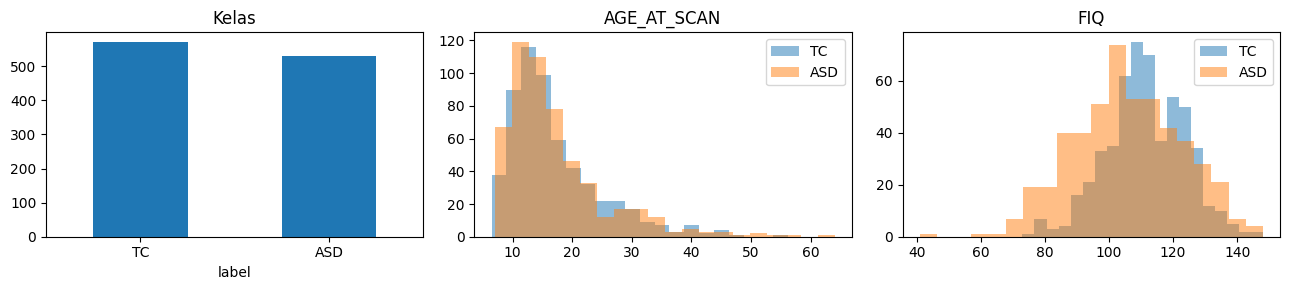

Cocok: 1102 | dipakai: 1102 | pusat: 17 | hasil: /kaggle/working/abide_results/full_stratified_f651365229


In [5]:
phenotype=pd.read_csv(PHENO_PATH,na_values=[-9999,"-9999","","N/A","n/a"])
required={"SUB_ID","DX_GROUP","SITE_ID","AGE_AT_SCAN","SEX","FIQ"}
assert required.issubset(phenotype.columns)
for col in ["SUB_ID","DX_GROUP","AGE_AT_SCAN","SEX","FIQ"]:
    phenotype[col]=pd.to_numeric(phenotype[col],errors="coerce")
assert phenotype.SUB_ID.notna().all() and phenotype.SUB_ID.is_unique
assert phenotype.DX_GROUP.isin([1,2]).all()
phenotype["SUB_ID"]=phenotype.SUB_ID.astype(int)
for col in ["AGE_AT_SCAN","FIQ"]:phenotype.loc[phenotype[col]<=0,col]=np.nan
phenotype.loc[~phenotype.SEX.isin([1,2]),"SEX"]=np.nan
phenotype["label"]=phenotype.DX_GROUP.map({1:1,2:0}).astype(int)
image_table=pd.DataFrame([{"SUB_ID":int(re.search(r"sub-(\d+)",r["name"]).group(1)),
    "image_path":str(local_files[r["name"]])} for r in drive_index])
assert image_table.SUB_ID.is_unique
cohort_all=phenotype.merge(image_table,on="SUB_ID",how="inner",validate="one_to_one").sort_values("SUB_ID")
assert cohort_all.SITE_ID.notna().all()
cohort_all["CENTER_ID"]=cohort_all.SITE_ID.str.replace(r"_\d+$","",regex=True)
if MODE=="smoke":
    cohort=cohort_all.groupby("label",group_keys=False).head(SMOKE_SUBJECTS//2)
else:cohort=cohort_all
cohort=cohort.sort_values("SUB_ID").reset_index(drop=True)
assert cohort.label.value_counts().min()>=N_FOLDS
CONFIG["cohort_ids"]=cohort.SUB_ID.tolist()
CONFIG["phenotype_sha256"]=PHENO_SHA
RUN_TAG=f"{MODE}_{CV_PROTOCOL}_"+digest_json(CONFIG)[:10]
OUT=RESULT_ROOT/RUN_TAG
OUT.mkdir(parents=True,exist_ok=True)
if RESUME_INPUT_ROOT:
    source=Path(RESUME_INPUT_ROOT)
    if (source/RUN_TAG).is_dir():source=source/RUN_TAG
    if not (source/"config.json").exists():raise FileNotFoundError("RESUME_INPUT_ROOT bukan direktori hasil run.")
    prior=json.loads((source/"config.json").read_text())
    if digest_json(prior)!=digest_json(CONFIG):raise ValueError("Konfigurasi resume berbeda; gunakan run baru.")
    if source.resolve()!=OUT.resolve():shutil.copytree(source,OUT,dirs_exist_ok=True)
atomic_json(CONFIG,OUT/"config.json");atomic_json(DATA_PROVENANCE,OUT/"data_provenance.json")
cohort_all.to_csv(OUT/"matched_all.csv",index=False);cohort.to_csv(OUT/"cohort_used.csv",index=False)
phenotype.loc[~phenotype.SUB_ID.isin(image_table.SUB_ID),["SUB_ID","DX_GROUP"]].to_csv(OUT/"phenotype_without_mri.csv",index=False)
image_table.loc[~image_table.SUB_ID.isin(phenotype.SUB_ID)].to_csv(OUT/"mri_without_phenotype.csv",index=False)
summary=cohort.groupby("label").agg(n=("SUB_ID","size"),age_mean=("AGE_AT_SCAN","mean"),fiq_mean=("FIQ","mean"))
summary.to_csv(OUT/"phenotype_summary.csv")
display(summary);display(cohort[["AGE_AT_SCAN","SEX","FIQ"]].isna().sum().rename("missing"))
site_counts=pd.crosstab(cohort.SITE_ID,cohort.label);site_counts.to_csv(OUT/"site_distribution.csv")
header_rows=[]
for row in cohort.itertuples(index=False):
    image=nib.load(row.image_path)
    if len(image.shape)!=3:raise ValueError(f"SUB_ID {row.SUB_ID}: bukan T1 3D")
    header_rows.append({"SUB_ID":row.SUB_ID,"shape":str(image.shape),"orientation":"".join(nib.aff2axcodes(image.affine)),
        "spacing":str(image.header.get_zooms()),"compressed_bytes":Path(row.image_path).stat().st_size})
pd.DataFrame(header_rows).to_csv(OUT/"mri_header_audit.csv",index=False)
fig,axes=plt.subplots(1,3,figsize=(13,3))
cohort.label.map({0:"TC",1:"ASD"}).value_counts().plot.bar(ax=axes[0],rot=0,title="Kelas")
for ax,col in zip(axes[1:],["AGE_AT_SCAN","FIQ"]):
    for label,group in cohort.groupby("label"):
        ax.hist(group[col].dropna(),bins=20,alpha=.5,label="ASD" if label else "TC")
    ax.set_title(col);ax.legend()
fig.tight_layout();fig.savefig(OUT/"eda.png",dpi=140);plt.show()
print("Cocok:",len(cohort_all),"| dipakai:",len(cohort),"| pusat:",cohort.CENTER_ID.nunique(),"| hasil:",OUT)

## 4. Skull stripping 3D dengan SynthStrip resmi

Jaringan referensi FreeSurfer (commit `cf4bccf24875a47245b4df9fc9372d0f1c3d784f`) disertakan
di bawah, bukan dieksekusi dari script remote. Bobot v1 diverifikasi SHA-256. Geometri memakai
adaptasi NiBabel, sehingga tidak numerik identik dengan CLI Surfa; mask native dan preview
disimpan untuk QC. Tidak ada fallback ke threshold/background sebagai pengganti skull stripping.

In [6]:
# Reference network: Hoopes et al., SynthStrip (2022), FreeSurfer.
# https://github.com/freesurfer/freesurfer/tree/cf4bccf24875a47245b4df9fc9372d0f1c3d784f/mri_synthstrip
class StripModel(nn.Module):

    def __init__(self, nb_features=16, nb_levels=7, feat_mult=2, max_features=64, nb_conv_per_level=2, max_pool=2, return_mask=False):
        super().__init__()
        ndims = 3
        if isinstance(nb_features, int):
            if nb_levels is None:
                raise ValueError('must provide unet nb_levels if nb_features is an integer')
            feats = np.round(nb_features * feat_mult ** np.arange(nb_levels)).astype(int)
            feats = np.clip(feats, 1, max_features)
            nb_features = [np.repeat(feats[:-1], nb_conv_per_level), np.repeat(np.flip(feats), nb_conv_per_level)]
        elif nb_levels is not None:
            raise ValueError('cannot use nb_levels if nb_features is not an integer')
        (enc_nf, dec_nf) = nb_features
        nb_dec_convs = len(enc_nf)
        final_convs = dec_nf[nb_dec_convs:]
        dec_nf = dec_nf[:nb_dec_convs]
        self.nb_levels = int(nb_dec_convs / nb_conv_per_level) + 1
        if isinstance(max_pool, int):
            max_pool = [max_pool] * self.nb_levels
        MaxPooling = getattr(nn, 'MaxPool%dd' % ndims)
        self.pooling = [MaxPooling(s) for s in max_pool]
        self.upsampling = [nn.Upsample(scale_factor=s, mode='nearest') for s in max_pool]
        prev_nf = 1
        encoder_nfs = [prev_nf]
        self.encoder = nn.ModuleList()
        for level in range(self.nb_levels - 1):
            convs = nn.ModuleList()
            for conv in range(nb_conv_per_level):
                nf = enc_nf[level * nb_conv_per_level + conv]
                convs.append(ConvBlock(ndims, prev_nf, nf))
                prev_nf = nf
            self.encoder.append(convs)
            encoder_nfs.append(prev_nf)
        encoder_nfs = np.flip(encoder_nfs)
        self.decoder = nn.ModuleList()
        for level in range(self.nb_levels - 1):
            convs = nn.ModuleList()
            for conv in range(nb_conv_per_level):
                nf = dec_nf[level * nb_conv_per_level + conv]
                convs.append(ConvBlock(ndims, prev_nf, nf))
                prev_nf = nf
            self.decoder.append(convs)
            if level < self.nb_levels - 1:
                prev_nf += encoder_nfs[level]
        self.remaining = nn.ModuleList()
        for (num, nf) in enumerate(final_convs):
            self.remaining.append(ConvBlock(ndims, prev_nf, nf))
            prev_nf = nf
        if return_mask:
            self.remaining.append(ConvBlock(ndims, prev_nf, 2, activation=None))
            self.remaining.append(nn.Softmax(dim=1))
        else:
            self.remaining.append(ConvBlock(ndims, prev_nf, 1, activation=None))

    def forward(self, x):
        x_history = [x]
        for (level, convs) in enumerate(self.encoder):
            for conv in convs:
                x = conv(x)
            x_history.append(x)
            x = self.pooling[level](x)
        for (level, convs) in enumerate(self.decoder):
            for conv in convs:
                x = conv(x)
            if level < self.nb_levels - 1:
                x = self.upsampling[level](x)
                x = torch.cat([x, x_history.pop()], dim=1)
        for conv in self.remaining:
            x = conv(x)
        return x

class ConvBlock(nn.Module):
    """
        Specific convolutional block followed by leakyrelu for unet.
        """

    def __init__(self, ndims, in_channels, out_channels, stride=1, activation='leaky'):
        super().__init__()
        Conv = getattr(nn, 'Conv%dd' % ndims)
        self.conv = Conv(in_channels, out_channels, 3, stride, 1)
        if activation == 'leaky':
            self.activation = nn.LeakyReLU(0.2)
        elif activation == None:
            self.activation = None
        else:
            raise ValueError(f'Unknown activation: {activation}')

    def forward(self, x):
        out = self.conv(x)
        if self.activation is not None:
            out = self.activation(out)
        return out

In [7]:
SYNTH_SHA="37417f802196186441aae3e7f385d94f8a98c64a88acaeaa2723af995c653e33"
SYNTH_URL="https://surfer.nmr.mgh.harvard.edu/docs/synthstrip/requirements/synthstrip.1.pt"
SYNTH_PATH=MODEL_CACHE/"synthstrip.1.pt"
http_fetch(SYNTH_URL,SYNTH_PATH,SYNTH_SHA)
strip_model=StripModel().to(DEVICE).eval()
strip_state=torch.load(SYNTH_PATH,map_location=DEVICE,weights_only=True)
strip_model.load_state_dict(strip_state["model_state_dict"],strict=True);del strip_state

def get_strip_model():
    global strip_model
    if "strip_model" not in globals():
        strip_model=StripModel().to(DEVICE).eval()
        state=torch.load(SYNTH_PATH,map_location=DEVICE,weights_only=True)
        strip_model.load_state_dict(state["model_state_dict"],strict=True)
    return strip_model

def brain_mask(image):
    lia=image.as_reoriented(nib.orientations.ornt_transform(nib.orientations.io_orientation(image.affine),
        nib.orientations.axcodes2ornt(("L","I","A"))))
    extent=np.asarray(lia.shape)*nib.affines.voxel_sizes(lia.affine)
    shape=tuple(np.maximum(192,np.ceil(extent/64).astype(int)*64))
    if max(shape)>320:raise ValueError("FOV >320 mm; periksa header sebelum melanjutkan.")
    aligned=conform(lia,out_shape=shape,voxel_size=(1.,1.,1.),order=0,orientation="LIA")
    data=aligned.get_fdata(dtype=np.float32);data-=data.min()
    scale=np.percentile(data,99)
    if not np.isfinite(scale) or scale<=0:raise ValueError("Volume kosong/invalid")
    data=np.clip(data/scale,0,1).astype(np.float32)
    # SynthStrip tetap FP32; AMP dipakai pada training encoder 2D.
    with torch.inference_mode():sdt=get_strip_model()(torch.from_numpy(data[None,None]).to(DEVICE)).squeeze().cpu().numpy()
    native=resample_from_to(nib.Nifti1Image(sdt,aligned.affine),(image.shape,image.affine),
        order=1,mode="constant",cval=100).get_fdata(dtype=np.float32)
    labels,count=ndi.label(native<1.)
    if count==0:raise ValueError("Mask SynthStrip kosong")
    sizes=np.bincount(labels.ravel());sizes[0]=0
    mask=ndi.binary_fill_holes(labels==sizes.argmax())
    if not .01<float(mask.mean())<.9:raise ValueError("Mask mencurigakan; inspeksi input/QC")
    return mask

def preprocessing_signature(path):
    stat=Path(path).stat()
    return {"input_sha256":sha256_file(path),"bytes":stat.st_size,"pipeline":PIPELINE_VERSION,
        "synthstrip_sha256":SYNTH_SHA,"shape":list(VOLUME_SHAPE),"image_size":IMAGE_SIZE,"slices":list(SLICE_FRACTIONS)}

def make_views(volume,mask128):
    intensity=np.clip((volume.astype(np.float32)+3.)/6.,0,1)
    intensity[~mask128]=0
    views=[]
    for axis in range(3):
        stack=np.stack([np.take(intensity,int(round(f*(intensity.shape[axis]-1))),axis=axis).T
            for f in SLICE_FRACTIONS])
        resized=F.interpolate(torch.from_numpy(stack.copy())[None],size=(IMAGE_SIZE,IMAGE_SIZE),mode="bilinear",align_corners=False)[0]
        views.append(np.rint(resized.numpy()*255).clip(0,255).astype(np.uint8))
    return np.stack(views)  # (3 bidang, 3 slice/kanal, 224, 224)

def preprocess_one(row):
    sid=int(row.SUB_ID);stem=f"sub-{sid:07d}"
    volume_path=VOLUMES/f"{stem}.npy";view_path=VIEWS/f"{stem}.npy"
    meta_path=VOLUMES/f"{stem}.json";mask_path=MASKS/f"{stem}_mask.nii.gz"
    signature=preprocessing_signature(row.image_path)
    if CACHE_INPUT_ROOT and not meta_path.exists():
        source=Path(CACHE_INPUT_ROOT);source_meta=source/"volumes"/f"{stem}.json"
        if source_meta.exists() and json.loads(source_meta.read_text()).get("signature")==signature:
            candidates=[(source/"volumes"/f"{stem}.npy",volume_path),
                (source/"views"/f"{stem}.npy",view_path),(source/"masks"/f"{stem}_mask.nii.gz",mask_path)]
            if all(a.is_file() for a,b in candidates):
                for a,b in candidates:shutil.copy2(a,b)
                shutil.copy2(source_meta,meta_path)
    if meta_path.exists() and volume_path.exists() and view_path.exists() and mask_path.exists():
        meta=json.loads(meta_path.read_text())
        if meta.get("signature")==signature:
            vol=np.load(volume_path,mmap_mode="r");views=np.load(view_path,mmap_mode="r")
            if (vol.shape==VOLUME_SHAPE and vol.dtype==np.float16 and views.dtype==np.uint8
                and views.shape==(3,3,IMAGE_SIZE,IMAGE_SIZE) and np.isfinite(vol).all()):
                return str(view_path),meta,True
    start=time.perf_counter()
    image=nib.as_closest_canonical(nib.load(row.image_path));values=image.get_fdata(dtype=np.float32)
    if not np.isfinite(values).all():raise ValueError(f"SUB_ID {sid}: voxel NaN/Inf")
    mask=brain_mask(image)
    nib.save(nib.Nifti1Image(mask.astype(np.uint8),image.affine),mask_path)
    coords=np.asarray(np.where(mask));low=np.maximum(coords.min(axis=1)-5,0);high=np.minimum(coords.max(axis=1)+6,image.shape)
    slices=tuple(slice(int(a),int(b)) for a,b in zip(low,high))
    crop=values[slices]*mask[slices]
    affine=image.affine.copy();affine[:3,3]=nib.affines.apply_affine(image.affine,low)
    target_affine=affine.copy();target_affine[:3,:3]=affine[:3,:3]@np.diag((np.asarray(crop.shape)-1)/(np.asarray(VOLUME_SHAPE)-1))
    target=(VOLUME_SHAPE,target_affine)
    resized=resample_from_to(nib.Nifti1Image(crop,affine),target,order=1).get_fdata(dtype=np.float32)
    mask128=resample_from_to(nib.Nifti1Image(mask[slices].astype(np.uint8),affine),target,order=0).get_fdata()>.5
    lo,hi=np.percentile(resized[mask128],[.5,99.5]);clipped=np.clip(resized,lo,hi)
    mean,std=float(clipped[mask128].mean()),float(clipped[mask128].std())
    if std<1e-6:raise ValueError(f"SUB_ID {sid}: intensitas konstan")
    normalized=np.where(mask128,(clipped-mean)/std,0).astype(np.float16)
    assert normalized.shape==VOLUME_SHAPE and np.isfinite(normalized).all()
    # Views dibuat dari float16 yang sama dengan cache agar hasil konsisten saat dipakai ulang.
    views=make_views(normalized,mask128)
    np.save(volume_path,normalized,allow_pickle=False);np.save(view_path,views,allow_pickle=False)
    meta={"SUB_ID":sid,"signature":signature,"mask_path":str(mask_path),"view_path":str(view_path),
        "volume_path":str(volume_path),"native_shape":list(image.shape),"output_affine":target_affine.tolist(),
        "mask_fraction":float(mask.mean()),"brain_volume_ml":float(mask.sum()*abs(np.linalg.det(image.affine[:3,:3]))/1000),
        "mean":mean,"std":std,"seconds":time.perf_counter()-start}
    atomic_json(meta,meta_path);gc.collect()
    return str(view_path),meta,False

## 5. Preprocessing gambar dan inspeksi hasil

Urutan: RAS → SynthStrip (grid LIA 1 mm) → mask kembali ke grid asli → largest connected
component → crop otak bermargin → resampling 128³ → clipping persentil otak 0,5–99,5 →
z-score hanya voxel otak. Mask diresample dengan nearest-neighbor, intensitas linear.
Seluruh operasi ini per subjek; tidak menggunakan distribusi cohort maupun label.
Tiga slice 40/50/60% pada setiap bidang menjadi kanal input 2.5D. Mean/std input pretrained
akan diterapkan per encoder dari konfigurasi `timm` saat forward.

SynthStrip + normalisasi + 2.5D:   0%|          | 0/1102 [00:00<?, ?it/s]

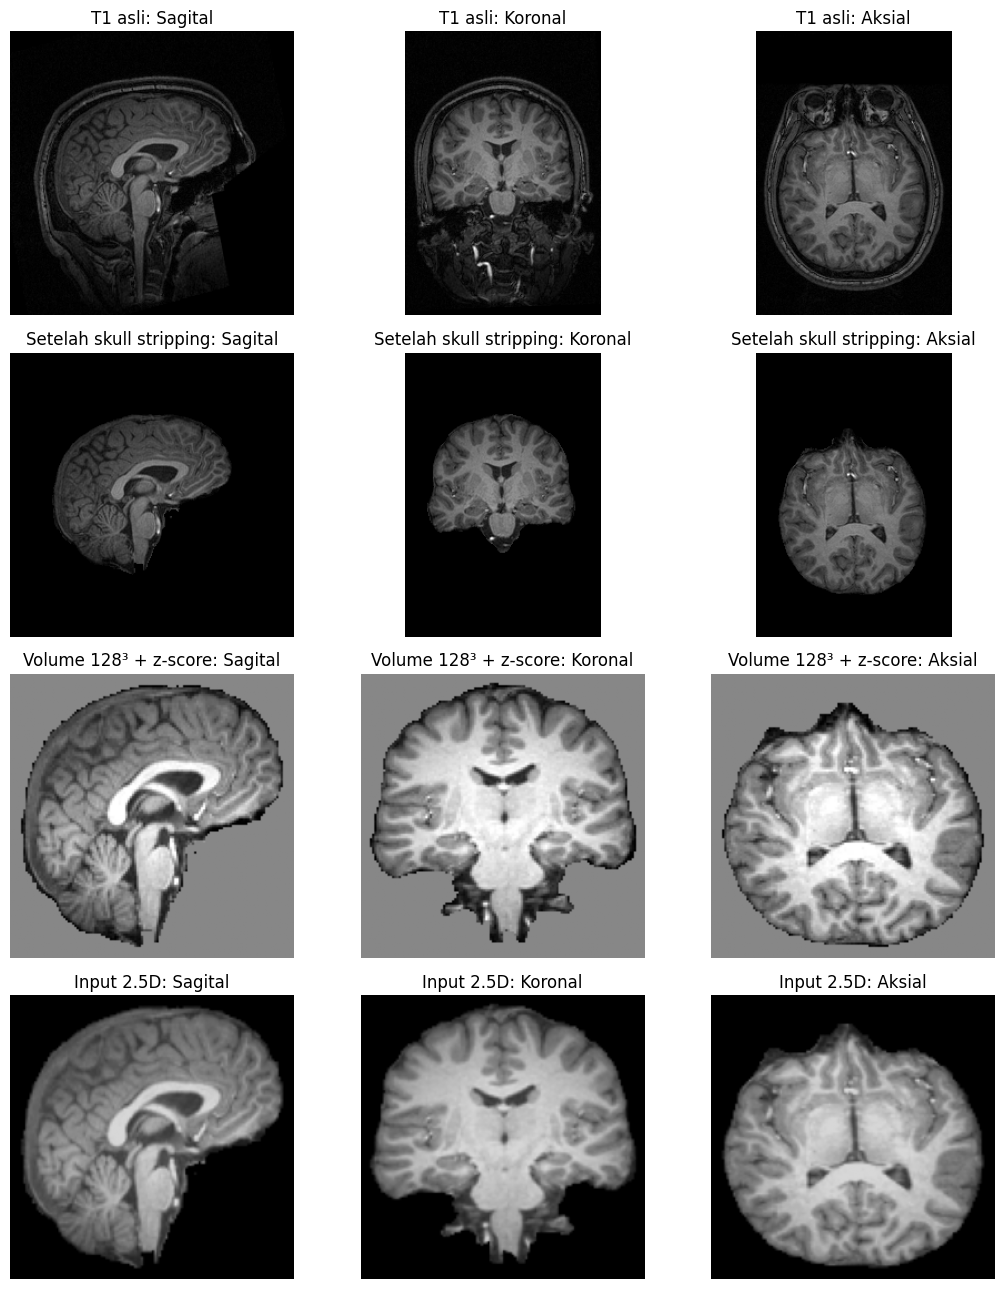

,SUB_ID,mask_fraction,brain_volume_ml,mean,std,seconds
count,1102.000,1102.000,1102.000,1102.000,1102.000,1102.000
mean,50748.161,0.148,1616.624,482.630,198.349,5.494
std,447.165,0.023,143.688,762.099,351.399,1.986
min,50002.000,0.090,1028.141,86.462,38.093,2.762
25%,50352.250,0.133,1526.419,191.089,81.003,4.357
50%,50709.500,0.145,1615.815,238.908,93.284,4.929
75%,51145.000,0.161,1710.561,372.303,120.851,5.781
max,51607.000,0.294,2243.163,6582.300,2683.999,12.592


In [8]:
preprocess_started=time.perf_counter();paths=[];qc=[];reused_count=0
for row in tqdm(cohort.itertuples(index=False),total=len(cohort),desc="SynthStrip + normalisasi + 2.5D"):
    path,meta,reused=preprocess_one(row);paths.append(path);reused_count+=int(reused)
    qc.append({k:meta[k] for k in ["SUB_ID","mask_fraction","brain_volume_ml","mean","std","seconds"]})
cohort["view_path"]=paths;cohort.to_csv(OUT/"cohort_used.csv",index=False)
CACHE_FINGERPRINT=digest_json([json.loads((VOLUMES/f"sub-{int(sid):07d}.json").read_text())["signature"] for sid in cohort.SUB_ID])
atomic_json({"fingerprint":CACHE_FINGERPRINT},OUT/"processed_fingerprint.json")
pd.DataFrame(qc).to_csv(OUT/"preprocessing_qc.csv",index=False)
atomic_json({"seconds":time.perf_counter()-preprocess_started,"subjects":len(cohort),"cache_reused":reused_count},OUT/"preprocessing_runtime.json")
del strip_model;gc.collect()
if DEVICE.type=="cuda":torch.cuda.empty_cache()
sample=cohort.iloc[0];stem=f"sub-{int(sample.SUB_ID):07d}"
native=nib.as_closest_canonical(nib.load(sample.image_path)).get_fdata(dtype=np.float32)
mask=nib.load(MASKS/f"{stem}_mask.nii.gz").get_fdata()>.5
volume=np.load(VOLUMES/f"{stem}.npy");views=np.load(sample.view_path)
fig,axes=plt.subplots(4,3,figsize=(11,13))
def center_views(a):return [a[a.shape[0]//2],a[:,a.shape[1]//2],a[:,:,a.shape[2]//2]]
for row_axes,array,title in zip(axes[:3],[native,native*mask,volume],["T1 asli","Setelah skull stripping","Volume 128³ + z-score"]):
    for ax,v,plane in zip(row_axes,center_views(array),["Sagital","Koronal","Aksial"]):
        ax.imshow(v.T,cmap="gray",origin="lower");ax.set_title(f"{title}: {plane}");ax.axis("off")
for ax,v,plane in zip(axes[3],views,["Sagital","Koronal","Aksial"]):
    ax.imshow(v[1],cmap="gray",vmin=0,vmax=255,origin="lower");ax.set_title(f"Input 2.5D: {plane}");ax.axis("off")
fig.tight_layout();fig.savefig(OUT/"preprocessing_preview.png",dpi=140);plt.show()
del native,mask,volume,views;gc.collect()
display(pd.DataFrame(qc).describe().round(3))

## 6. Split subjek, validasi internal dan preprocessing tabular

Default: stratified 5-fold. Early stopping hanya memakai validation dari outer training,
bukan outer test. Alternatif `CV_PROTOCOL="center_group"` memisahkan 17 pusat: suffix _1/_2
pada LEUVEN/UCLA/UM digabung; split validation juga memisahkan pusat. Mode itu dijalankan
sebagai eksperimen terpisah karena biayanya bertambah. Tidak ada slice dari subjek sama
yang dipisahkan ke train/test.

Age/FIQ: median + missing indicators + StandardScaler; Sex: mode + one-hot. Transformasi
di-fit pada inner training. SUB_ID, SITE_ID, CENTER_ID, diagnosis dan skor ADOS/ADI tidak
menjadi prediktor. Tidak ada SMOTE atau augmentasi pada validation/test.

In [9]:
PHENO_COLS=["AGE_AT_SCAN","SEX","FIQ"]

def make_tab_preprocessor():
    numeric=Pipeline([("impute",SimpleImputer(strategy="median",add_indicator=True,keep_empty_features=True)),
        ("scale",StandardScaler())])
    sex=Pipeline([("impute",SimpleImputer(strategy="most_frequent",keep_empty_features=True)),
        ("onehot",OneHotEncoder(categories=[[1.,2.]],handle_unknown="ignore",sparse_output=False))])
    return ColumnTransformer([("numeric",numeric,["AGE_AT_SCAN","FIQ"]),("sex",sex,["SEX"])],remainder="drop")

if CV_PROTOCOL=="stratified":
    outer=StratifiedKFold(N_FOLDS,shuffle=True,random_state=SEED).split(cohort,cohort.label)
else:
    assert cohort.CENTER_ID.nunique()>=N_FOLDS
    outer=StratifiedGroupKFold(N_FOLDS,shuffle=True,random_state=SEED).split(cohort,cohort.label,cohort.CENTER_ID)
folds=[];split_rows=[]
for fold,(outer_train,test) in enumerate(outer,1):
    if CV_PROTOCOL=="stratified":
        val_size=max(2,math.ceil(.2*len(outer_train)))
        train,val=train_test_split(outer_train,test_size=val_size,stratify=cohort.iloc[outer_train].label,random_state=SEED+fold)
    else:
        inner_frame=cohort.iloc[outer_train]
        inner=StratifiedGroupKFold(min(5,inner_frame.CENTER_ID.nunique()),shuffle=True,random_state=SEED+fold)
        ti,vi=next(inner.split(inner_frame,inner_frame.label,inner_frame.CENTER_ID))
        train,val=outer_train[ti],outer_train[vi]
    assert not(set(train)&set(val) or set(train)&set(test) or set(val)&set(test))
    assert set(train)|set(val)|set(test)==set(range(len(cohort)))
    for part,idx in [("train",train),("validation",val),("test",test)]:
        assert set(cohort.iloc[idx].label)=={0,1}
        for i in idx:split_rows.append({"fold":fold,"partition":part,"SUB_ID":int(cohort.iloc[i].SUB_ID),
            "SITE_ID":cohort.iloc[i].SITE_ID,"CENTER_ID":cohort.iloc[i].CENTER_ID,"label":int(cohort.iloc[i].label)})
    if CV_PROTOCOL=="center_group":
        gs=[set(cohort.iloc[idx].CENTER_ID) for idx in (train,val,test)]
        assert not(gs[0]&gs[1] or gs[0]&gs[2] or gs[1]&gs[2])
    folds.append((train,val,test))
assignments=pd.DataFrame(split_rows);assignments.to_csv(OUT/"fold_assignments.csv",index=False)
tests=assignments[assignments.partition=="test"]
assert tests.groupby("SUB_ID").size().eq(1).all()
display(assignments.groupby(["fold","partition","label"]).size().unstack(fill_value=0))
FOLDS_TO_RUN=list(range(1,N_FOLDS+1))[:FOLD_LIMIT or N_FOLDS]
print("Fold yang dijalankan:",FOLDS_TO_RUN)

label              0    1
fold partition           
1    test        114  107
     train       365  339
     validation   92   85
2    test        115  106
     train       364  340
     validation   92   85
3    test        114  106
     train       365  340
     validation   92   85
4    test        114  106
     train       365  340
     validation   92   85
5    test        114  106
     train       365  340
     validation   92   85

Fold yang dijalankan: [1, 2, 3, 4, 5]


## 7. Model citra multi-view dan MLP

Encoder memakai bobot pretrained `timm`, lalu global representation tiga bidang dirata-rata
dan diproyeksikan ke 128 dimensi. Epoch pemanasan melatih projection/head; setelah itu
dua blok akhir ViT/DeiT atau stage akhir Swin + norm dibuka. Bagian frozen tetap eval agar
dropout tidak mengubah extractor frozen. DeiT memakai representasi class/distillation token
pretrained; fine-tuning ASD tidak membutuhkan teacher tambahan.

MLP tabular/fusion: Dense 64 → GELU → Dropout → Dense 32 → GELU → Dropout → satu logit.
Augmentasi citra berupa jitter intensitas kecil pada training saja. Normalisasi pretrained
per encoder diterapkan di dalam model. T4 memakai FP16 autocast/GradScaler; SynthStrip FP32.

In [10]:
class ViewDataset(Dataset):
    def __init__(self,indices):self.frame=cohort.iloc[indices].reset_index(drop=True)
    def __len__(self):return len(self.frame)
    def __getitem__(self,i):
        row=self.frame.iloc[i]
        x=torch.from_numpy(np.load(row.view_path,allow_pickle=False).copy())
        return x,torch.tensor(float(row.label),dtype=torch.float32)

class MultiViewClassifier(nn.Module):
    def __init__(self,alias,pretrained=True):
        super().__init__();self.alias=alias
        self.encoder=timm.create_model(MODEL_IDS[alias],pretrained=pretrained,num_classes=0)
        cfg=resolve_model_data_config(self.encoder)
        assert cfg["input_size"]==(3,IMAGE_SIZE,IMAGE_SIZE)
        self.register_buffer("image_mean",torch.tensor(cfg["mean"]).reshape(1,3,1,1))
        self.register_buffer("image_std",torch.tensor(cfg["std"]).reshape(1,3,1,1))
        self.input_config={k:cfg[k] for k in ("mean","std","input_size","interpolation")}
        self.projection=nn.Sequential(nn.LayerNorm(self.encoder.num_features),nn.Linear(self.encoder.num_features,LATENT_DIM),
            nn.GELU(),nn.Dropout(DROPOUT))
        self.classifier=nn.Linear(LATENT_DIM,1)
        for p in self.encoder.parameters():p.requires_grad=False
        tail=list(self.encoder.blocks[-TAIL_BLOCKS:]) if alias in {"vit","deit"} else [self.encoder.layers[-1]]
        for attr in ("norm","fc_norm"):
            module=getattr(self.encoder,attr,None)
            if module is not None:tail.append(module)
        self.tail_modules=tuple(tail)
        self.finetune_enabled=True
        self.set_phase(WARMUP_EPOCHS+1)

    @property
    def tail_parameters(self):
        # Baca Parameter saat ini, termasuk setelah .to(cuda) mengganti objek Parameter.
        parameters=[];seen=set()
        for module in self.tail_modules:
            for p in module.parameters():
                if id(p) not in seen:parameters.append(p);seen.add(id(p))
        return parameters

    def set_phase(self,epoch):
        self.finetune_enabled=epoch>WARMUP_EPOCHS
        for p in self.tail_parameters:p.requires_grad=self.finetune_enabled

    def train(self,mode=True):
        super().train(mode)
        self.encoder.eval()
        if mode and self.finetune_enabled:
            for module in self.tail_modules:module.train(True)
        return self

    def embed(self,x):
        if x.ndim!=5 or x.shape[1:3]!=(3,3):raise ValueError(f"Perlu (B,3,3,H,W), diterima {tuple(x.shape)}")
        batch,views=x.shape[:2];x=x.float()/255.
        if self.training:
            gain=torch.empty(batch,1,1,1,1,device=x.device).uniform_(.95,1.05)
            x=(x*gain+torch.randn_like(x)*.005).clamp(0,1)
        x=x.flatten(0,1);x=(x-self.image_mean)/self.image_std
        z=self.encoder(x)
        if isinstance(z,(tuple,list)):z=torch.stack(z).mean(0)
        z=z.reshape(batch,views,-1).mean(1)
        return self.projection(z)

    def forward(self,x):return self.classifier(self.embed(x)).squeeze(1)

class TabularMLP(nn.Module):
    def __init__(self,n_features):
        super().__init__();self.network=nn.Sequential(nn.Linear(n_features,64),nn.GELU(),nn.Dropout(DROPOUT),
            nn.Linear(64,32),nn.GELU(),nn.Dropout(DROPOUT),nn.Linear(32,1))
    def forward(self,x):return self.network(x).squeeze(1)

def make_loaders(datasets,batch_size,seed,workers):
    generator=torch.Generator().manual_seed(seed)
    result=[]
    for j,dataset in enumerate(datasets):
        result.append(DataLoader(dataset,batch_size=batch_size,shuffle=j==0,
            generator=generator if j==0 else torch.Generator().manual_seed(seed+123+j),
            num_workers=workers,pin_memory=DEVICE.type=="cuda",persistent_workers=workers>0))
    return result,generator

def array_datasets(arrays,indices):
    return [TensorDataset(torch.from_numpy(np.asarray(a,dtype=np.float32)),
        torch.from_numpy(cohort.iloc[idx].label.to_numpy(dtype=np.float32))) for a,idx in zip(arrays,indices)]

## 8. Training dengan early stopping, checkpoint dan resume

Loss BCE berbobot kelas dihitung dari inner training. Validation loss memilih checkpoint;
test hanya diprediksi setelah model terbaik dimuat. AdamW, cosine schedule, gradient
accumulation, clipping dan AMP dipakai pada encoder. State optimizer/scheduler/scaler,
RNG dan generator shuffle disimpan pada batas epoch. Hasil job yang selesai dapat dipakai
ulang hanya jika signature data/split/konfigurasinya cocok. Partial run tidak diberi status complete.

In [11]:
def rng_state(generator):
    state=np.random.get_state()
    return {"python":random.getstate(),"numpy_name":state[0],"numpy_keys":state[1].tolist(),
        "numpy_pos":state[2],"numpy_gauss":state[3],"numpy_cached":state[4],
        "torch":torch.get_rng_state(),"cuda":torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [],
        "loader":generator.get_state()}

def restore_rng(state,generator):
    random.setstate(state["python"])
    np.random.set_state((state["numpy_name"],np.asarray(state["numpy_keys"],dtype=np.uint32),
        state["numpy_pos"],state["numpy_gauss"],state["numpy_cached"]))
    torch.set_rng_state(state["torch"].cpu());generator.set_state(state["loader"].cpu())
    if state["cuda"] and torch.cuda.is_available():
        torch.cuda.set_rng_state_all([x.cpu() for x in state["cuda"][:torch.cuda.device_count()]])

def job_signature(kind,fold,indices,extra=None):
    return digest_json({"config":CONFIG,"processed":CACHE_FINGERPRINT,"kind":kind,"fold":fold,
        "ids":[cohort.iloc[idx].SUB_ID.tolist() for idx in indices],"extra":extra})

def predict_torch(model,loader,device):
    model.eval();prob=[]
    with torch.inference_mode():
        for x,y in loader:
            with autocast_for(device):logit=model(x.to(device,non_blocking=True))
            prob.extend(torch.sigmoid(logit.float()).cpu().numpy().tolist())
    p=np.asarray(prob,dtype=np.float64)
    if not np.isfinite(p).all():raise FloatingPointError("Probabilitas NaN/Inf")
    return p

def eval_loss(model,loader,criterion,device):
    model.eval();total=0.;n=0
    with torch.inference_mode():
        for x,y in loader:
            x,y=x.to(device,non_blocking=True),y.to(device)
            with autocast_for(device):loss=criterion(model(x),y)
            if not torch.isfinite(loss):raise FloatingPointError("Validation loss NaN/Inf")
            total+=float(loss)*len(y);n+=len(y)
    return total/n

def torch_job(model,loaders,generator,optimizer,device,epochs,patience,prefix,signature,spec,positive_weight):
    prefix=Path(prefix);best_path=prefix.with_name(prefix.name+"_best.pt")
    last_path=prefix.with_name(prefix.name+"_last.pt");done_path=prefix.with_name(prefix.name+"_done.json")
    model=model.to(device)
    if RESUME and done_path.exists() and best_path.exists():
        info=json.loads(done_path.read_text())
        if info.get("signature")==signature:
            best=torch.load(best_path,map_location=device,weights_only=True)
            if best.get("signature")!=signature:raise ValueError("Signature best checkpoint berbeda")
            model.load_state_dict(best["state_dict"]);model.eval()
            print("REUSE",prefix.name,flush=True);return model,info
    criterion=nn.BCEWithLogitsLoss(pos_weight=torch.tensor(positive_weight,dtype=torch.float32,device=device))
    scaler=torch.amp.GradScaler("cuda",enabled=device.type=="cuda")
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=epochs)
    start_epoch,best_loss,stale,history,elapsed_before=1,float("inf"),0,[],0.
    if RESUME and last_path.exists():
        last=torch.load(last_path,map_location=device,weights_only=True)
        if last.get("signature")!=signature:raise ValueError("Checkpoint last berbeda; jangan campur konfigurasi")
        model.load_state_dict(last["state_dict"]);optimizer.load_state_dict(last["optimizer"])
        scheduler.load_state_dict(last["scheduler"]);scaler.load_state_dict(last["scaler"])
        start_epoch=last["epoch"]+1;best_loss=last["best_loss"];stale=last["stale"]
        history=last["history"];elapsed_before=last["elapsed_seconds"]
        restore_rng(last["rng"],generator)
        print("RESUME",prefix.name,"epoch",start_epoch,flush=True)
        del last
    started=time.perf_counter()
    if device.type=="cuda":torch.cuda.reset_peak_memory_stats(device)
    for epoch in range(start_epoch,epochs+1):
        if stale>=patience:break
        if hasattr(model,"set_phase"):model.set_phase(epoch)
        model.train();optimizer.zero_grad(set_to_none=True);total=0.;n=0
        for step,(x,y) in enumerate(loaders[0]):
            x,y=x.to(device,non_blocking=True),y.to(device)
            with autocast_for(device):loss=criterion(model(x),y)
            if not torch.isfinite(loss):raise FloatingPointError("Training loss NaN/Inf")
            accumulation=ACCUMULATION_STEPS if device.type=="cuda" else 1
            group_start=(step//accumulation)*accumulation
            group_samples=min(accumulation*loaders[0].batch_size,len(loaders[0].dataset)-group_start*loaders[0].batch_size)
            scaler.scale(loss*len(y)/group_samples).backward()
            if (step+1)%accumulation==0 or step+1==len(loaders[0]):
                scaler.unscale_(optimizer);nn.utils.clip_grad_norm_(model.parameters(),1.)
                scaler.step(optimizer);scaler.update();optimizer.zero_grad(set_to_none=True)
            total+=float(loss.detach())*len(y);n+=len(y)
        val_loss=eval_loss(model,loaders[1],criterion,device);scheduler.step()
        history.append({"epoch":epoch,"train_loss":total/n,"validation_loss":val_loss})
        if val_loss<best_loss-1e-5:
            best_loss,stale=val_loss,0
            atomic_torch({"state_dict":model.state_dict(),"signature":signature,"spec":spec,
                "epoch":epoch,"validation_loss":val_loss},best_path)
        else:stale+=1
        elapsed=elapsed_before+time.perf_counter()-started
        atomic_torch({"state_dict":model.state_dict(),"signature":signature,"spec":spec,"epoch":epoch,
            "optimizer":optimizer.state_dict(),"scheduler":scheduler.state_dict(),"scaler":scaler.state_dict(),
            "best_loss":best_loss,"stale":stale,"history":history,"elapsed_seconds":elapsed,
            "rng":rng_state(generator)},last_path)
        pd.DataFrame(history).to_csv(prefix.with_name(prefix.name+"_history.csv"),index=False)
        print(f"{prefix.name} | epoch {epoch}/{epochs}: train={total/n:.4f}, val={val_loss:.4f}",flush=True)
    best=torch.load(best_path,map_location=device,weights_only=True)
    if best["signature"]!=signature:raise ValueError("Checkpoint best tidak sesuai")
    model.load_state_dict(best["state_dict"]);model.eval()
    info={"signature":signature,"best_epoch":best["epoch"],"best_validation_loss":best["validation_loss"],
        "epochs_ran":len(history),"elapsed_seconds":elapsed_before+time.perf_counter()-started,
        "peak_gpu_gib":float(torch.cuda.max_memory_allocated(device)/1024**3) if device.type=="cuda" else 0.,
        "device":str(device),"parameters":sum(p.numel() for p in model.parameters()),
        "max_trainable_parameters":sum(p.numel() for p in model.parameters() if p.requires_grad),"spec":spec}
    atomic_json(info,done_path);return model,info

def train_mlp(arrays,indices,prefix,signature):
    seed_everything(SEED+int(indices[0][0]))
    datasets=array_datasets(arrays,indices);loaders,generator=make_loaders(datasets,TAB_BATCH_SIZE,SEED,0)
    model=TabularMLP(arrays[0].shape[1]).to(TAB_DEVICE)
    optimizer=torch.optim.AdamW(model.parameters(),lr=MLP_LR,weight_decay=WEIGHT_DECAY)
    labels=cohort.iloc[indices[0]].label.to_numpy();weight=float((labels==0).sum()/(labels==1).sum())
    with threadpool_limits(limits=CPU_THREADS):
        model,info=torch_job(model,loaders,generator,optimizer,TAB_DEVICE,MLP_EPOCHS,MLP_PATIENCE,prefix,
            signature,{"kind":"mlp","n_features":int(arrays[0].shape[1]),"hidden":[64,32],"dropout":DROPOUT},weight)
        predictions=[predict_torch(model,loader,TAB_DEVICE) for loader in loaders[1:]]
    del model,optimizer,loaders;gc.collect();return predictions,info

def train_lightgbm(arrays,indices,prefix,signature):
    prefix=Path(prefix);path=prefix.with_suffix(".joblib");meta_path=prefix.with_name(prefix.name+"_done.json")
    frames=[pd.DataFrame(a,columns=[f"f_{i}" for i in range(a.shape[1])]) for a in arrays]
    if RESUME and path.exists() and meta_path.exists() and json.loads(meta_path.read_text()).get("signature")==signature:
        model=joblib.load(path);info=json.loads(meta_path.read_text());print("REUSE",prefix.name,flush=True)
    else:
        started=time.perf_counter()
        model=lgb.LGBMClassifier(n_estimators=LGB_ROUNDS,num_leaves=7,max_depth=3,learning_rate=.03,
            min_child_samples=20,reg_alpha=.1,reg_lambda=1.,colsample_bytree=.9,
            class_weight="balanced",random_state=SEED,n_jobs=CPU_THREADS,
            deterministic=True,force_col_wise=True,verbosity=-1,device_type="cpu")
        model.fit(frames[0],cohort.iloc[indices[0]].label.to_numpy(),
            eval_set=[(frames[1],cohort.iloc[indices[1]].label.to_numpy())],eval_metric="binary_logloss",
            callbacks=[lgb.early_stopping(40,first_metric_only=True,verbose=False),lgb.log_evaluation(0)])
        joblib.dump(model,path)
        info={"signature":signature,"best_epoch":int(model.best_iteration_),"epochs_ran":int(model.n_estimators_),
            "elapsed_seconds":time.perf_counter()-started,"peak_gpu_gib":0.,"device":"cpu", "spec":{"kind":"lightgbm","n_features":arrays[0].shape[1]}}
        atomic_json(info,meta_path)
    predictions=[model.predict_proba(a,num_iteration=model.best_iteration_)[:,list(model.classes_).index(1)] for a in frames[1:]]
    if any(not np.isfinite(p).all() for p in predictions):raise FloatingPointError("LightGBM probabilities invalid")
    return predictions,info

## 9. Fine-tuning citra, ekstraksi latent dan fusion per fold

Encoder setiap fold dilatih hanya pada inner training dan dipilih lewat validation. Setelah itu,
embedding train/validation/test diekstrak dari checkpoint terbaik dalam mode eval. StandardScaler
embedding di-fit pada inner training, lalu digabung dengan fenotipik yang sudah ditransformasi.
MLP/LightGBM fusion dilatih pada train, early stopping di validation, dan dievaluasi di test.

Tidak ada PCA atau statistik citra cohort global. Input 128³ dan views dapat dipakai ulang
karena preprocessing per subjek tidak memakai label. Embedding supervised **khusus fold**;
cache embedding memakai hash checkpoint, sehingga tidak tercampur antar fold/model.

In [12]:
def train_vision(alias,fold,indices,prefix,signature):
    seed_everything(SEED+fold)
    prefix=Path(prefix);last=prefix.with_name(prefix.name+"_last.pt");done=prefix.with_name(prefix.name+"_done.json")
    reusable=RESUME and (last.exists() or (done.exists() and json.loads(done.read_text()).get("signature")==signature))
    model=MultiViewClassifier(alias,pretrained=PRETRAINED and not reusable).to(DEVICE)
    loaders,generator=make_loaders([ViewDataset(idx) for idx in indices],BATCH_SIZE,SEED+fold,NUM_WORKERS)
    head=list(model.projection.parameters())+list(model.classifier.parameters())
    optimizer=torch.optim.AdamW([{"params":head,"lr":CV_HEAD_LR},
        {"params":model.tail_parameters,"lr":CV_BACKBONE_LR}],weight_decay=WEIGHT_DECAY)
    labels=cohort.iloc[indices[0]].label.to_numpy();weight=float((labels==0).sum()/(labels==1).sum())
    spec={"kind":"cv","alias":alias,"timm_id":MODEL_IDS[alias],"input_config":model.input_config,
        "latent_dim":LATENT_DIM,"tail_blocks":TAIL_BLOCKS,"dropout":DROPOUT}
    try:
        model,info=torch_job(model,loaders,generator,optimizer,DEVICE,CV_EPOCHS,CV_PATIENCE,prefix,signature,spec,weight)
    except torch.cuda.OutOfMemoryError as exc:
        raise RuntimeError("VRAM tidak cukup. Ubah BATCH_SIZE ke 2 (run tag baru); tetap gunakan FP16.") from exc
    probabilities=[predict_torch(model,loader,DEVICE) for loader in loaders[1:]]
    best_path=prefix.with_name(prefix.name+"_best.pt");best_sha=sha256_file(best_path)
    embedding_path=prefix.with_name(prefix.name+"_embeddings.npz");embedding_meta=prefix.with_name(prefix.name+"_embeddings.json")
    fingerprint=digest_json({"signature":signature,"best_sha256":best_sha,"ids":[cohort.iloc[i].SUB_ID.tolist() for i in indices]})
    if embedding_path.exists() and embedding_meta.exists() and json.loads(embedding_meta.read_text()).get("fingerprint")==fingerprint:
        with np.load(embedding_path,allow_pickle=False) as packed:embeddings=[packed[k].copy() for k in ("train","val","test")]
    else:
        model.eval();embeddings=[]
        for idx in indices:
            loader=DataLoader(ViewDataset(idx),batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS,
                pin_memory=DEVICE.type=="cuda")
            parts=[]
            with torch.inference_mode():
                for x,y in loader:
                    with autocast_for(DEVICE):z=model.embed(x.to(DEVICE,non_blocking=True))
                    parts.append(z.float().cpu().numpy())
            embeddings.append(np.concatenate(parts))
        np.savez_compressed(embedding_path,train=embeddings[0],val=embeddings[1],test=embeddings[2])
        atomic_json({"fingerprint":fingerprint,"checkpoint_sha256":best_sha},embedding_meta)
    for a,idx in zip(embeddings,indices):assert a.shape==(len(idx),LATENT_DIM) and np.isfinite(a).all()
    del model,optimizer,loaders;gc.collect()
    if DEVICE.type=="cuda":torch.cuda.empty_cache()
    return probabilities,embeddings,info,best_sha

def metrics_binary(truth,p):
    truth=np.asarray(truth,dtype=int);p=np.asarray(p,dtype=float);pred=(p>=.5).astype(int)
    tn,fp,fn,tp=confusion_matrix(truth,pred,labels=[0,1]).ravel()
    return {"accuracy":accuracy_score(truth,pred),"balanced_accuracy":balanced_accuracy_score(truth,pred),
        "precision":precision_score(truth,pred,zero_division=0),"recall":recall_score(truth,pred,zero_division=0),
        "specificity":tn/(tn+fp) if tn+fp else np.nan,"f1":f1_score(truth,pred,zero_division=0),
        "roc_auc":roc_auc_score(truth,p) if len(np.unique(truth))==2 else np.nan,
        "tn":int(tn),"fp":int(fp),"fn":int(fn),"tp":int(tp)}

def prediction_frame(name,fold,idx,p):
    assert len(p)==len(idx) and np.isfinite(p).all()
    frame=cohort.iloc[idx][["SUB_ID","SITE_ID","CENTER_ID","label"]].copy()
    frame["experiment"]=name;frame["fold"]=fold;frame["probability_asd"]=p;frame["prediction"]=(np.asarray(p)>=.5).astype(int)
    return frame

In [13]:
prediction_tables=[];metric_records=[];fit_records=[]
EXPECTED_EXPERIMENTS=["tab_MLP","tab_LightGBM"]+[f"{a}_image" for a in MODEL_IDS]+[f"{a}+{t}" for a in MODEL_IDS for t in ("MLP","LightGBM")]
for fold in FOLDS_TO_RUN:
    train,val,test=folds[fold-1];indices=(train,val,test)
    fold_dir=OUT/f"fold_{fold}";fold_dir.mkdir(exist_ok=True)
    preprocessor=make_tab_preprocessor()
    tab=[preprocessor.fit_transform(cohort.iloc[train][PHENO_COLS]).astype(np.float32),
        preprocessor.transform(cohort.iloc[val][PHENO_COLS]).astype(np.float32),
        preprocessor.transform(cohort.iloc[test][PHENO_COLS]).astype(np.float32)]
    assert all(np.isfinite(a).all() for a in tab)
    joblib.dump(preprocessor,fold_dir/"tab_preprocessor.joblib")
    for family in ("MLP","LightGBM"):
        name=f"tab_{family}";signature=job_signature(name,fold,indices)
        function=train_mlp if family=="MLP" else train_lightgbm
        predictions,info=function(tab,indices,fold_dir/name,signature)
        frame=prediction_frame(name,fold,test,predictions[1]);prediction_tables.append(frame)
        metric_records.append({"experiment":name,"fold":fold,**metrics_binary(frame.label,frame.probability_asd)})
        fit_records.append({"experiment":name,"fold":fold,**info})
    for alias in MODEL_IDS:
        name=f"{alias}_image";signature=job_signature(name,fold,indices)
        cv_prob,latent,info,best_sha=train_vision(alias,fold,indices,fold_dir/name,signature)
        frame=prediction_frame(name,fold,test,cv_prob[1]);prediction_tables.append(frame)
        metric_records.append({"experiment":name,"fold":fold,**metrics_binary(frame.label,frame.probability_asd)})
        fit_records.append({"experiment":name,"fold":fold,**info})
        latent_scaler=StandardScaler().fit(latent[0])
        fusion=[np.concatenate([latent_scaler.transform(z).astype(np.float32),x],axis=1) for z,x in zip(latent,tab)]
        joblib.dump(latent_scaler,fold_dir/f"{alias}_latent_scaler.joblib")
        for family in ("MLP","LightGBM"):
            name=f"{alias}+{family}";prefix=fold_dir/f"{alias}_fusion_{family}"
            signature=job_signature(name,fold,indices,{"encoder_best_sha256":best_sha})
            function=train_mlp if family=="MLP" else train_lightgbm
            predictions,info=function(fusion,indices,prefix,signature)
            frame=prediction_frame(name,fold,test,predictions[1]);prediction_tables.append(frame)
            metric_records.append({"experiment":name,"fold":fold,**metrics_binary(frame.label,frame.probability_asd)})
            fit_records.append({"experiment":name,"fold":fold,**info})
    pd.concat(prediction_tables,ignore_index=True).to_csv(OUT/"oof_predictions.csv",index=False)
    pd.DataFrame(metric_records).to_csv(OUT/"metrics_per_fold.csv",index=False)
    atomic_json(fit_records,OUT/"fit_records.json")
    atomic_json({"status":"partial","completed_folds":[f for f in FOLDS_TO_RUN if f<=fold],
        "expected_folds":N_FOLDS,"experiments":EXPECTED_EXPERIMENTS},OUT/"run_status.json")
    print(f"SELESAI fold {fold}; {len(EXPECTED_EXPERIMENTS)} konfigurasi",flush=True)
oof=pd.concat(prediction_tables,ignore_index=True);fold_metrics=pd.DataFrame(metric_records)
assert set(oof.experiment)==set(EXPECTED_EXPERIMENTS)
assert oof.groupby(["experiment","SUB_ID"]).size().eq(1).all()
COMPLETE=len(FOLDS_TO_RUN)==N_FOLDS
for name,frame in oof.groupby("experiment"):
    expected_ids=set(cohort.iloc[np.concatenate([folds[f-1][2] for f in FOLDS_TO_RUN])].SUB_ID)
    assert set(frame.SUB_ID)==expected_ids
    if COMPLETE:assert len(frame)==len(cohort)
print("Semua OOF valid | complete:",COMPLETE,"| rows:",len(oof))

tab_MLP | epoch 1/80: train=0.7223, val=0.7154
tab_MLP | epoch 2/80: train=0.7094, val=0.7094
tab_MLP | epoch 3/80: train=0.7022, val=0.7038
tab_MLP | epoch 4/80: train=0.6973, val=0.6991
tab_MLP | epoch 5/80: train=0.6907, val=0.6972
tab_MLP | epoch 6/80: train=0.6858, val=0.6955
tab_MLP | epoch 7/80: train=0.6837, val=0.6953
tab_MLP | epoch 8/80: train=0.6793, val=0.6950
tab_MLP | epoch 9/80: train=0.6807, val=0.6950
tab_MLP | epoch 10/80: train=0.6763, val=0.6949
tab_MLP | epoch 11/80: train=0.6799, val=0.6955
tab_MLP | epoch 12/80: train=0.6728, val=0.6951
tab_MLP | epoch 13/80: train=0.6764, val=0.6951
tab_MLP | epoch 14/80: train=0.6704, val=0.6952
tab_MLP | epoch 15/80: train=0.6720, val=0.6967
tab_MLP | epoch 16/80: train=0.6698, val=0.6969
tab_MLP | epoch 17/80: train=0.6697, val=0.6974
tab_MLP | epoch 18/80: train=0.6729, val=0.6974
tab_MLP | epoch 19/80: train=0.6724, val=0.6973
tab_MLP | epoch 20/80: train=0.6708, val=0.6971


model.safetensors:   0%|          | 0.00/22.9M [00:00<?, ?B/s]

vit_image | epoch 1/12: train=0.7366, val=0.7270
vit_image | epoch 2/12: train=0.7130, val=0.7170
vit_image | epoch 3/12: train=0.7070, val=0.7533
vit_image | epoch 4/12: train=0.6940, val=0.7401
vit_image | epoch 5/12: train=0.6887, val=0.7469
vit_image | epoch 6/12: train=0.6884, val=0.7628
vit_fusion_MLP | epoch 1/80: train=0.7092, val=0.7179
vit_fusion_MLP | epoch 2/80: train=0.6882, val=0.7294
vit_fusion_MLP | epoch 3/80: train=0.6670, val=0.7431
vit_fusion_MLP | epoch 4/80: train=0.6581, val=0.7523
vit_fusion_MLP | epoch 5/80: train=0.6430, val=0.7550
vit_fusion_MLP | epoch 6/80: train=0.6304, val=0.7663
vit_fusion_MLP | epoch 7/80: train=0.6151, val=0.7748
vit_fusion_MLP | epoch 8/80: train=0.6012, val=0.7806
vit_fusion_MLP | epoch 9/80: train=0.5778, val=0.7839
vit_fusion_MLP | epoch 10/80: train=0.5644, val=0.7933
vit_fusion_MLP | epoch 11/80: train=0.5560, val=0.8079


model.safetensors:   0%|          | 0.00/23.7M [00:00<?, ?B/s]

deit_image | epoch 1/12: train=0.7335, val=0.7296
deit_image | epoch 2/12: train=0.7196, val=0.7173
deit_image | epoch 3/12: train=0.7154, val=0.7429
deit_image | epoch 4/12: train=0.7073, val=0.7175
deit_image | epoch 5/12: train=0.7067, val=0.7226
deit_image | epoch 6/12: train=0.7120, val=0.7204
deit_fusion_MLP | epoch 1/80: train=0.7148, val=0.7155
deit_fusion_MLP | epoch 2/80: train=0.7019, val=0.7161
deit_fusion_MLP | epoch 3/80: train=0.6835, val=0.7183
deit_fusion_MLP | epoch 4/80: train=0.6720, val=0.7258
deit_fusion_MLP | epoch 5/80: train=0.6552, val=0.7205
deit_fusion_MLP | epoch 6/80: train=0.6355, val=0.7196
deit_fusion_MLP | epoch 7/80: train=0.6234, val=0.7195
deit_fusion_MLP | epoch 8/80: train=0.5953, val=0.7283
deit_fusion_MLP | epoch 9/80: train=0.5785, val=0.7377
deit_fusion_MLP | epoch 10/80: train=0.5689, val=0.7499
deit_fusion_MLP | epoch 11/80: train=0.5408, val=0.7601


model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

swin_image | epoch 1/12: train=0.7589, val=0.7628
swin_image | epoch 2/12: train=0.7303, val=0.7232
swin_image | epoch 3/12: train=0.7100, val=0.8676
swin_image | epoch 4/12: train=0.6827, val=0.8041
swin_image | epoch 5/12: train=0.6766, val=0.7510
swin_image | epoch 6/12: train=0.6632, val=0.7698
swin_fusion_MLP | epoch 1/80: train=0.7063, val=0.7165
swin_fusion_MLP | epoch 2/80: train=0.6765, val=0.7351
swin_fusion_MLP | epoch 3/80: train=0.6577, val=0.7592
swin_fusion_MLP | epoch 4/80: train=0.6542, val=0.7576
swin_fusion_MLP | epoch 5/80: train=0.6368, val=0.7550
swin_fusion_MLP | epoch 6/80: train=0.6261, val=0.7553
swin_fusion_MLP | epoch 7/80: train=0.6106, val=0.7683
swin_fusion_MLP | epoch 8/80: train=0.6000, val=0.7738
swin_fusion_MLP | epoch 9/80: train=0.5893, val=0.7713
swin_fusion_MLP | epoch 10/80: train=0.5783, val=0.7940
swin_fusion_MLP | epoch 11/80: train=0.5545, val=0.8122
SELESAI fold 1; 11 konfigurasi
tab_MLP | epoch 1/80: train=0.7138, val=0.7105
tab_MLP | epoch

## 10. Evaluasi akhir dan ablasi

Accuracy, balanced accuracy, precision, recall/sensitivity ASD, specificity TC, F1, ROC-AUC
dihitung per fold dan gabungan OOF. AUC memakai probabilitas. Tabel mean ± SD fold berbeda
dari metrik pooled OOF; SD fold bukan confidence interval. Ablasi mencakup citra-only,
tabular-only dan enam kombinasi fusion. Variasi sumber pretraining/kapasitas model dicatat;
peringkat OOF bersifat deskriptif, bukan skor test eksternal setelah pemilihan model.

accuracy         balanced_accuracy         precision          \
                  mean     std              mean     std      mean     std   
experiment                                                                   
deit+LightGBM   0.5844  0.0411            0.5815  0.0414    0.5791  0.0493   
deit+MLP        0.5036  0.0278            0.5074  0.0266    0.4906  0.0267   
deit_image      0.5227  0.0445            0.5215  0.0408    0.5115  0.0437   
swin+LightGBM   0.6017  0.0170            0.5994  0.0160    0.5995  0.0282   
swin+MLP        0.5436  0.0359            0.5442  0.0318    0.5314  0.0412   
swin_image      0.5381  0.0430            0.5411  0.0374    0.5581  0.1222   
tab_LightGBM    0.5980  0.0398            0.5939  0.0389    0.6101  0.0565   
tab_MLP         0.5980  0.0153            0.5930  0.0154    0.6121  0.0226   
vit+LightGBM    0.6089  0.0353            0.6063  0.0353    0.6074  0.0415   
vit+MLP         0.5172  0.0514            0.5198  0.0488    0.5045  0.0469   
vit_image       0.5245  0.0304            0.5178  0.0251    0.5651  0.1145   

               recall         specificity              f1         roc_auc  \
                 mean     std        mean     std    mean     std    mean   
experiment                                                                  
deit+LightGBM  0.5011  0.0718      0.6620  0.0490  0.5360  0.0575  0.6038   
deit+MLP       0.6177  0.2064      0.3970  0.2070  0.5338  0.0778  0.5393   
deit_image     0.4969  0.1909      0.5461  0.2248  0.4854  0.1049  0.5164   
swin+LightGBM  0.5331  0.0531      0.6657  0.0650  0.5623  0.0239  0.6278   
swin+MLP       0.5650  0.1054      0.5234  0.1576  0.5413  0.0298  0.5766   
swin_image     0.6284  0.2734      0.4538  0.3114  0.5416  0.1218  0.5756   
tab_LightGBM   0.4785  0.0583      0.7093  0.0859  0.5334  0.0419  0.6161   
tab_MLP        0.4539  0.0362      0.7320  0.0310  0.5206  0.0258  0.6113   
vit+LightGBM   0.5331  0.0502      0.6795  0.0413  0.5673  0.0433  0.6090   
vit+MLP        0.5952  0.0858      0.4445  0.1474  0.5421  0.0329  0.5479   
vit_image      0.3333  0.1881      0.7023  0.2194  0.3734  0.1576  0.5462   

                       
                  std  
experiment             
deit+LightGBM  0.0414  
deit+MLP       0.0488  
deit_image     0.0384  
swin+LightGBM  0.0222  
swin+MLP       0.0250  
swin_image     0.0348  
tab_LightGBM   0.0357  
tab_MLP        0.0336  
vit+LightGBM   0.0371  
vit+MLP        0.0422  
vit_image      0.0498

,n,accuracy,balanced_accuracy,precision,recall,specificity,f1,roc_auc,tn,fp,fn,tp
experiment,,,,,,,,,,,,
deit+LightGBM,1102,0.5844,0.5815,0.5795,0.5009,0.6620,0.5374,0.5986,378,193,265,266
deit+MLP,1102,0.5036,0.5076,0.4881,0.6177,0.3975,0.5453,0.5318,227,344,203,328
deit_image,1102,0.5227,0.5218,0.5048,0.4972,0.5464,0.5009,0.5103,312,259,267,264
swin+LightGBM,1102,0.6016,0.5992,0.5970,0.5330,0.6655,0.5632,0.6238,380,191,248,283
swin+MLP,1102,0.5436,0.5443,0.5245,0.5650,0.5236,0.5440,0.5718,299,272,231,300
swin_image,1102,0.5381,0.5413,0.5170,0.6290,0.4536,0.5675,0.5618,259,312,197,334
tab_LightGBM,1102,0.5980,0.5938,0.6048,0.4783,0.7093,0.5342,0.6125,405,166,277,254
tab_MLP,1102,0.5980,0.5930,0.6117,0.4539,0.7320,0.5211,0.6083,418,153,290,241
vit+LightGBM,1102,0.6089,0.6062,0.6073,0.5330,0.6795,0.5677,0.6093,388,183,248,283


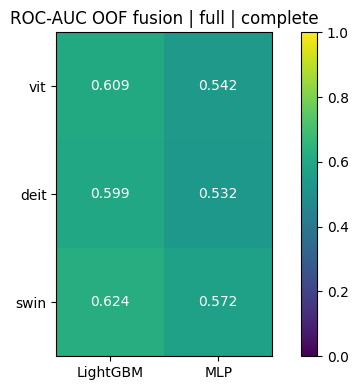

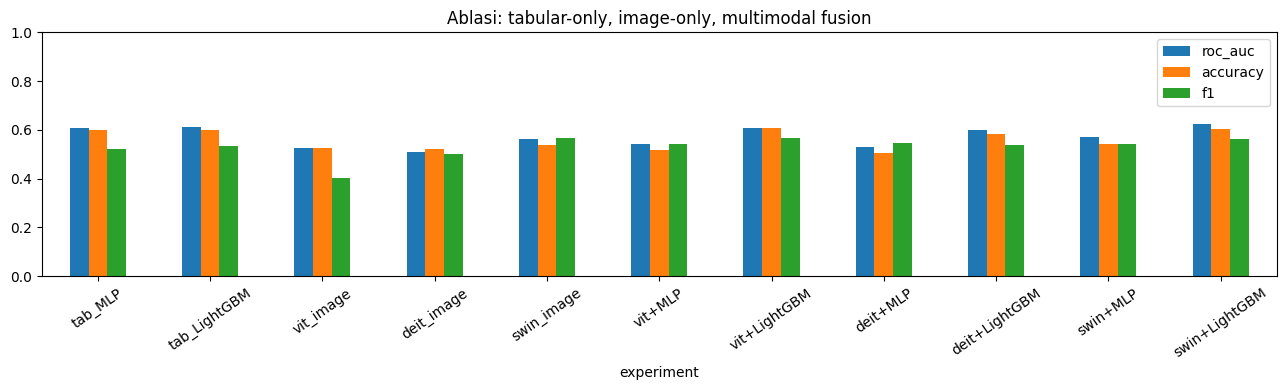

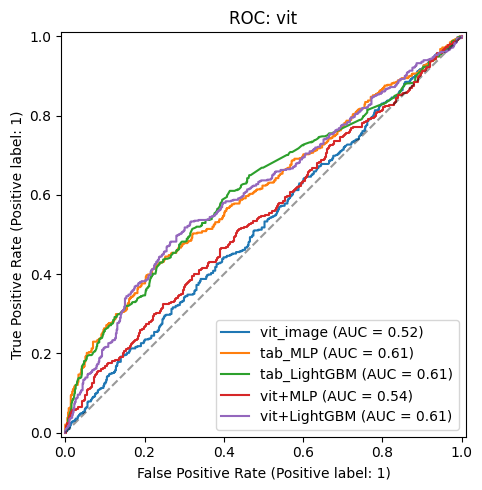

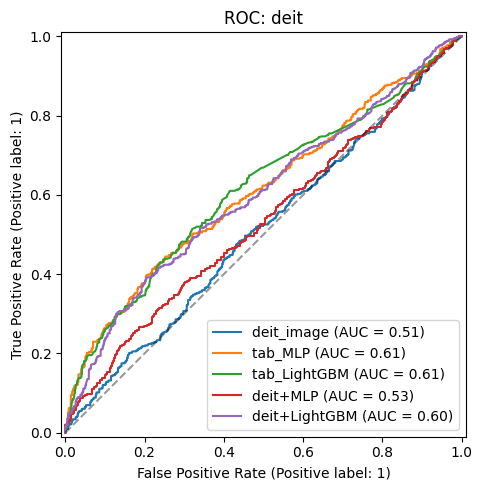

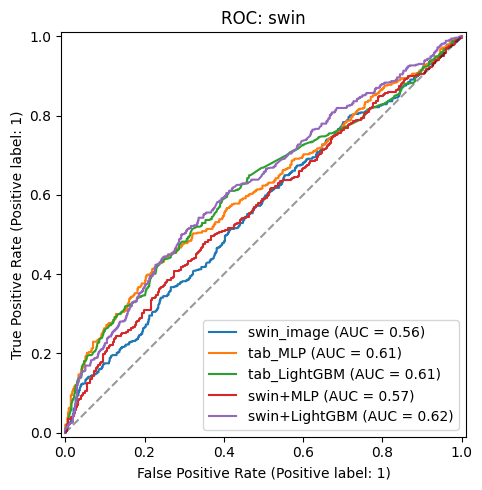

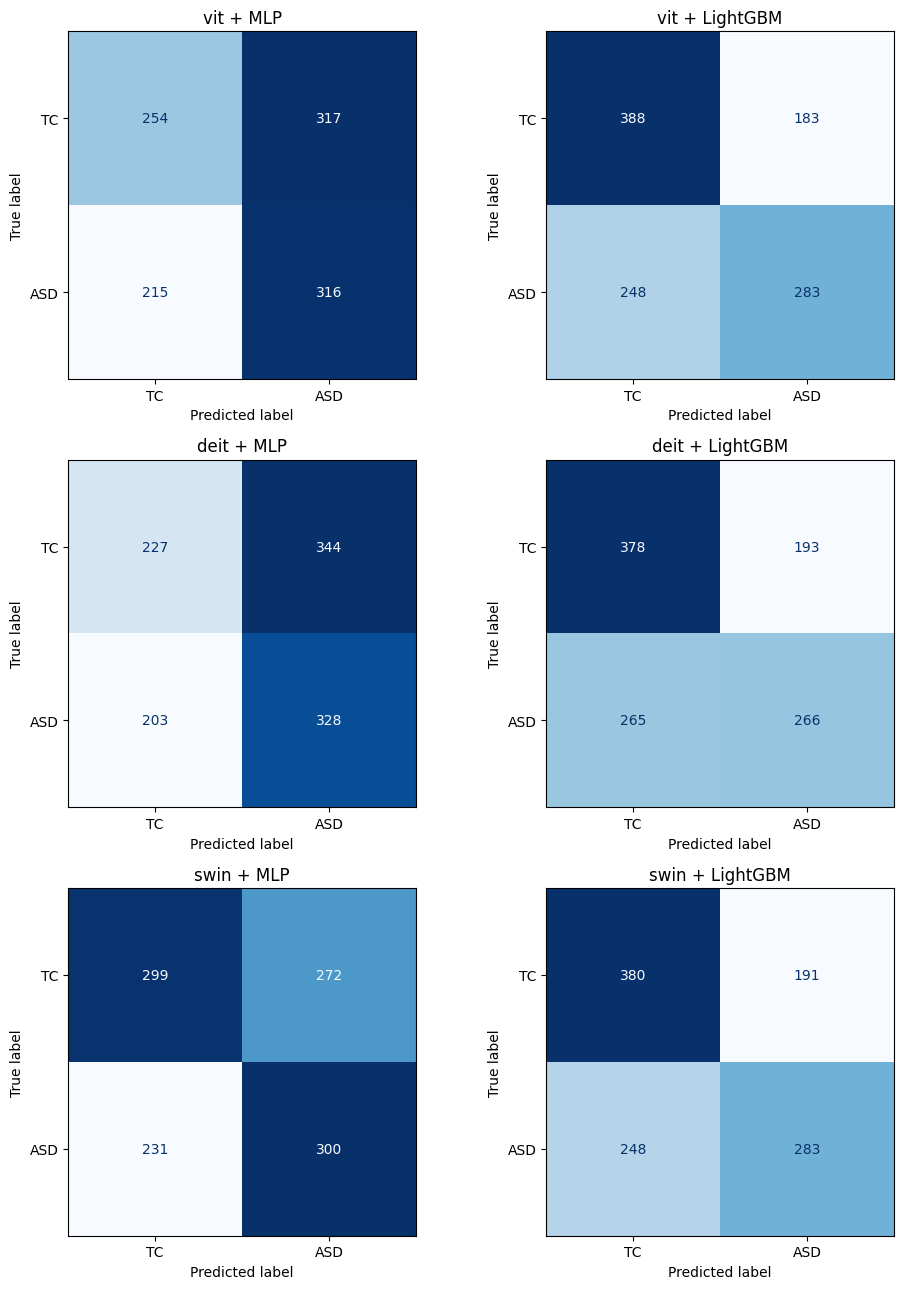

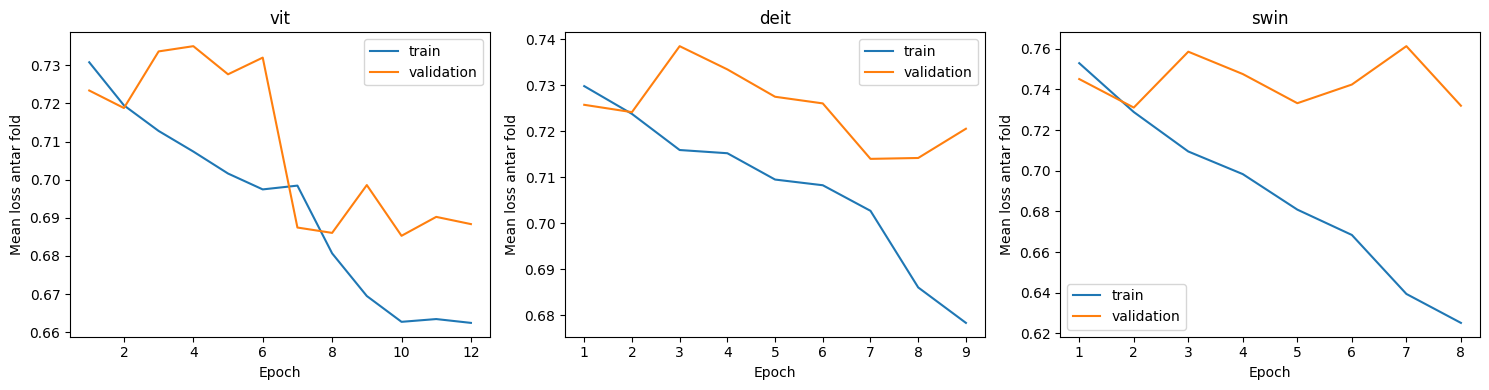

In [14]:
METRICS=["accuracy","balanced_accuracy","precision","recall","specificity","f1","roc_auc"]
summary=fold_metrics.groupby("experiment")[METRICS].agg(["mean","std"])
pooled=pd.DataFrame([{"experiment":name,"n":len(frame),**metrics_binary(frame.label,frame.probability_asd)}
    for name,frame in oof.groupby("experiment")]).set_index("experiment")
summary.to_csv(OUT/"metrics_mean_std.csv");pooled.to_csv(OUT/"metrics_pooled_oof.csv")
display(summary.round(4));display(pooled.round(4))
if not COMPLETE:print("PARTIAL RUN: tabel hanya fold yang selesai; belum evaluasi seluruh cohort.")
reports={name:classification_report(frame.label,frame.prediction,labels=[0,1],target_names=["TC","ASD"],
    output_dict=True,zero_division=0) for name,frame in oof.groupby("experiment")}
atomic_json(reports,OUT/"classification_reports.json")
site_metrics=[]
for (name,center),frame in oof.groupby(["experiment","CENTER_ID"]):
    site_metrics.append({"experiment":name,"CENTER_ID":center,"n":len(frame),**metrics_binary(frame.label,frame.probability_asd)})
pd.DataFrame(site_metrics).to_csv(OUT/"metrics_per_center.csv",index=False)

fusion_table=pd.DataFrame([{ "encoder":a,"classifier":t,
    "roc_auc":float(pooled.loc[f"{a}+{t}","roc_auc"]),"accuracy":float(pooled.loc[f"{a}+{t}","accuracy"])}
    for a in MODEL_IDS for t in ("MLP","LightGBM")])
fusion_table.to_csv(OUT/"fusion_comparison.csv",index=False)
heatmap=fusion_table.pivot(index="encoder",columns="classifier",values="roc_auc").reindex(list(MODEL_IDS))
fig,ax=plt.subplots(figsize=(6,4));im=ax.imshow(heatmap.to_numpy(),vmin=0,vmax=1,cmap="viridis")
ax.set_xticks(range(len(heatmap.columns)),heatmap.columns);ax.set_yticks(range(len(heatmap.index)),heatmap.index)
for r in range(len(heatmap)):
    for c in range(len(heatmap.columns)):ax.text(c,r,f"{heatmap.iloc[r,c]:.3f}",ha="center",va="center",color="white")
ax.set_title(f"ROC-AUC OOF fusion | {MODE} | {'complete' if COMPLETE else 'PARTIAL'}")
fig.colorbar(im,ax=ax);fig.tight_layout();fig.savefig(OUT/"fusion_auc_heatmap.png",dpi=150);plt.show()
fig,ax=plt.subplots(figsize=(13,4))
pooled.reindex(EXPECTED_EXPERIMENTS)[["roc_auc","accuracy","f1"]].plot.bar(ax=ax,rot=35)
ax.set_ylim(0,1);ax.set_title("Ablasi: tabular-only, image-only, multimodal fusion")
fig.tight_layout();fig.savefig(OUT/"ablation_comparison.png",dpi=140);plt.show()
for alias in MODEL_IDS:
    fig,ax=plt.subplots(figsize=(6,5))
    for name in [f"{alias}_image","tab_MLP","tab_LightGBM",f"{alias}+MLP",f"{alias}+LightGBM"]:
        frame=oof[oof.experiment==name]
        RocCurveDisplay.from_predictions(frame.label,frame.probability_asd,name=name,ax=ax)
    ax.plot([0,1],[0,1],"k--",alpha=.4);ax.set_title(f"ROC: {alias}")
    fig.tight_layout();fig.savefig(OUT/f"roc_{alias}.png",dpi=140);plt.show()
fig,axes=plt.subplots(3,2,figsize=(10,13))
for r,alias in enumerate(MODEL_IDS):
    for c,family in enumerate(("MLP","LightGBM")):
        frame=oof[oof.experiment==f"{alias}+{family}"]
        ConfusionMatrixDisplay.from_predictions(frame.label,frame.prediction,labels=[0,1],display_labels=["TC","ASD"],
            ax=axes[r,c],cmap="Blues",colorbar=False)
        axes[r,c].set_title(f"{alias} + {family}")
fig.tight_layout();fig.savefig(OUT/"fusion_confusion_matrices.png",dpi=140);plt.show()
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,alias in zip(axes,MODEL_IDS):
    records=[]
    for fold in FOLDS_TO_RUN:
        path=OUT/f"fold_{fold}"/f"{alias}_image_history.csv"
        if path.exists():records.append(pd.read_csv(path))
    curve=pd.concat(records).groupby("epoch")[["train_loss","validation_loss"]].mean()
    ax.plot(curve.index,curve.train_loss,label="train");ax.plot(curve.index,curve.validation_loss,label="validation")
    ax.set(title=alias,xlabel="Epoch",ylabel="Mean loss antar fold");ax.legend()
fig.tight_layout();fig.savefig(OUT/"vision_training_curves.png",dpi=140);plt.show()

## 11. Pemeriksaan reload dan inferensi multimodal

Contoh memakai test subject dari fold pertama yang dijalankan, untuk pasangan referensi
ViT+MLP yang ditetapkan sebelumnya. Checkpoint CV, latent scaler, preprocessor tabular dan
classifier fusion dimuat ulang; probabilitas harus cocok dengan OOF. Fungsi juga mendukung
DeiT/Swin dan LightGBM. Input baru memakai preprocessing identik dan ID subjek yang unik.
Checkpoint per fold dapat dipakai untuk inferensi subjek baru; ini tidak otomatis menjadi
model deployment final yang divalidasi eksternal. Prediksi ulang data training tidak dipakai
sebagai evaluasi akhir.

In [15]:
def predict_fold_subject(row,fold=1,alias="vit",family="MLP"):
    if alias not in MODEL_IDS or family not in {"MLP","LightGBM"}:raise ValueError("Pasangan model tidak dikenal")
    cleaned={}
    for col in PHENO_COLS:cleaned[col]=pd.to_numeric(row[col],errors="coerce")
    for col in ["AGE_AT_SCAN","FIQ"]:
        if not np.isfinite(cleaned[col]) or cleaned[col]<=0:cleaned[col]=np.nan
    if cleaned["SEX"] not in [1,2]:cleaned["SEX"]=np.nan
    # Jalur cached maupun input baru memakai prosedur yang sama.
    view_path,metadata,reused=preprocess_one(row)
    if "strip_model" in globals():
        del globals()["strip_model"];gc.collect()
        if DEVICE.type=="cuda":torch.cuda.empty_cache()
    fold_dir=OUT/f"fold_{fold}"
    saved=torch.load(fold_dir/f"{alias}_image_best.pt",map_location=DEVICE,weights_only=True)
    model=MultiViewClassifier(alias,pretrained=False).to(DEVICE);model.load_state_dict(saved["state_dict"]);model.eval()
    x=torch.from_numpy(np.load(view_path,allow_pickle=False).copy())[None].to(DEVICE)
    with torch.inference_mode(),autocast_for(DEVICE):latent=model.embed(x)
    latent=latent.float().cpu().numpy()
    scaler=joblib.load(fold_dir/f"{alias}_latent_scaler.joblib")
    preprocessor=joblib.load(fold_dir/"tab_preprocessor.joblib")
    tab=preprocessor.transform(pd.DataFrame([cleaned],columns=PHENO_COLS)).astype(np.float32)
    fusion=np.concatenate([scaler.transform(latent).astype(np.float32),tab],axis=1)
    if family=="MLP":
        classifier_state=torch.load(fold_dir/f"{alias}_fusion_MLP_best.pt",map_location=TAB_DEVICE,weights_only=True)
        classifier=TabularMLP(classifier_state["spec"]["n_features"]).to(TAB_DEVICE)
        classifier.load_state_dict(classifier_state["state_dict"]);classifier.eval()
        with torch.inference_mode():probability=float(torch.sigmoid(classifier(torch.from_numpy(fusion).to(TAB_DEVICE))).item())
        del classifier,classifier_state
    else:
        classifier=joblib.load(fold_dir/f"{alias}_fusion_LightGBM.joblib")
        features=pd.DataFrame(fusion,columns=classifier.feature_name_)
        probability=float(classifier.predict_proba(features,num_iteration=classifier.best_iteration_)[:,list(classifier.classes_).index(1)][0])
    del model,saved,x;gc.collect()
    if DEVICE.type=="cuda":torch.cuda.empty_cache()
    return {"SUB_ID":int(row.SUB_ID),"fold":fold,"encoder":alias,"tabular":family,
        "probability_asd":probability,"prediction":"ASD" if probability>=.5 else "TC"}

reference_fold=FOLDS_TO_RUN[0]
reference=cohort.iloc[folds[reference_fold-1][2][0]]
inference=predict_fold_subject(reference,reference_fold,"vit","MLP")
expected=oof[(oof.experiment=="vit+MLP")&(oof.SUB_ID==int(reference.SUB_ID))].iloc[0]
assert np.isclose(inference["probability_asd"],expected.probability_asd,atol=2e-3)
display(pd.DataFrame([inference]));print("Reload + inferensi cocok dengan prediksi OOF.")

,SUB_ID,fold,encoder,tabular,probability_asd,prediction
0,50003,1,vit,MLP,0.413733,TC


Reload + inferensi cocok dengan prediksi OOF.


## 12. Ringkasan, kelengkapan eksperimen dan export

Status `complete` hanya diberikan jika semua 5 fold dan 11 konfigurasi memiliki tepat satu
prediksi test OOF untuk setiap subjek. Mode smoke tetap ditandai sebagai uji alur walaupun
kelima fold selesai. Laporan, hasil numerik, grafik, preprocessor/scaler dan checkpoint
disimpan; raw/cache tidak dimasukkan ke ZIP hasil. Simpan cache terpisah jika ingin menghindari
pengunduhan/preprocessing pada sesi berikutnya.

In [16]:
validation={"status":"complete" if COMPLETE else "partial","mode":MODE,"protocol":CV_PROTOCOL,
    "subjects":len(cohort),"completed_folds":FOLDS_TO_RUN,"expected_folds":N_FOLDS,
    "experiments":EXPECTED_EXPERIMENTS,"expected_configurations_per_fold":11,"oof_rows":len(oof),
    "unique_oof_per_subject_per_experiment":True,"finite_oof":bool(np.isfinite(oof.probability_asd).all()),
    "image_encoder_families":list(MODEL_IDS),"tabular_families":["MLP","LightGBM"],
    "reload_inference_matches_oof":True,"device":str(DEVICE),"gpu_execution":DEVICE.type=="cuda",
    "t4_hardware_verified":DEVICE.type=="cuda" and "T4" in torch.cuda.get_device_name(0),
    "research_result":MODE=="full" and COMPLETE}
atomic_json(validation,OUT/"run_status.json");atomic_json(validation,OUT/"run_validation.json")
environment={"python":sys.version,"packages":{name:version(name) for name in
    ["torch","torchvision","timm","lightgbm","numpy","pandas","scipy","scikit-learn","nibabel","gdown"]},
    "cuda_available":torch.cuda.is_available(),"cuda_version":torch.version.cuda,
    "gpu_names":[torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())]}
atomic_json(environment,OUT/"environment.json")
report=["# ABIDE Kaggle T4: laporan eksperimen","",
    f"Status: **{validation['status']}**, mode **{MODE}**, protokol **{CV_PROTOCOL}**.",
    f"Subjek: {len(cohort)}; fold selesai: {FOLDS_TO_RUN}; eksperimen per fold: 11.",
    f"Perangkat training citra: {DEVICE}. MLP dan LightGBM tabular/fusion: CPU.","",
    "## Perbandingan fusion (pooled OOF)","",
    "| Encoder | Classifier | Accuracy | ROC-AUC |","|---|---|---:|---:|",
    *[f"| {r.encoder} | {r.classifier} | {r.accuracy:.4f} | {r.roc_auc:.4f} |" for r in fusion_table.itertuples()],"",
    "## Interpretasi dan batas validasi","",
    "Citra-only dan tabular-only disimpan bersama fusion pada metrics_per_fold.csv, metrics_mean_std.csv dan metrics_pooled_oof.csv.",
    "Perubahan skor fusion terhadap unimodal bersifat deskriptif; belum ada uji signifikansi peningkatan atau test eksternal setelah pemilihan model.",
    "Adaptasi menggunakan multi-view 2.5D dari volume otak 3D, bukan 3D Transformer penuh. Registrasi atlas/harmonisasi antar scanner tidak dilakukan otomatis.",
    "ViT memakai pretraining ImageNet-21k lalu 1k; DeiT/Swin memakai ImageNet-1k, dengan jumlah parameter berbeda. Perbandingan bukan isolasi efek arsitektur saja.",
    "Mask SynthStrip memakai adaptasi NiBabel dan perlu QC. Age/Sex/FIQ diproses hanya dengan statistik inner training.",
    "SD fold bukan confidence interval. Protokol stratified mengevaluasi campuran site; center_group memisahkan pusat acquisition.",
    "Checkpoint menyimpan best/last per fold, bukan model final hasil tuning yang memiliki validasi independen.",
    "MODE smoke atau status partial tidak boleh dilaporkan sebagai hasil penelitian seluruh cohort.","",
    "## Isi output","",
    "config.json, data_provenance.json, environment.json, fold_assignments.csv, preprocessing_qc.csv, oof_predictions.csv, metrics_*.csv, fusion_comparison.csv, fit_records.json, run_validation.json, grafik dan folder checkpoint fold.",
]
report_text="\n".join(report);(OUT/"experiment_report.md").write_text(report_text,encoding="utf-8")
display(Markdown(report_text))
if EXPORT_ZIP:
    archive=RESULT_ROOT/f"{RUN_TAG}_results.zip"
    with zipfile.ZipFile(archive,"w",compression=zipfile.ZIP_DEFLATED,compresslevel=1) as bundle:
        for path in OUT.rglob("*"):
            if path.is_file() and not path.name.endswith(".tmp"):bundle.write(path,arcname=str(Path(RUN_TAG)/path.relative_to(OUT)))
    print("ZIP hasil:",archive);display(FileLink(str(archive)))
print("Direktori hasil:",OUT)

# ABIDE Kaggle T4: laporan eksperimen

Status: **complete**, mode **full**, protokol **stratified**.
Subjek: 1102; fold selesai: [1, 2, 3, 4, 5]; eksperimen per fold: 11.
Perangkat training citra: cuda:0. MLP dan LightGBM tabular/fusion: CPU.

## Perbandingan fusion (pooled OOF)

| Encoder | Classifier | Accuracy | ROC-AUC |
|---|---|---:|---:|
| vit | MLP | 0.5172 | 0.5419 |
| vit | LightGBM | 0.6089 | 0.6093 |
| deit | MLP | 0.5036 | 0.5318 |
| deit | LightGBM | 0.5844 | 0.5986 |
| swin | MLP | 0.5436 | 0.5718 |
| swin | LightGBM | 0.6016 | 0.6238 |

## Interpretasi dan batas validasi

Citra-only dan tabular-only disimpan bersama fusion pada metrics_per_fold.csv, metrics_mean_std.csv dan metrics_pooled_oof.csv.
Perubahan skor fusion terhadap unimodal bersifat deskriptif; belum ada uji signifikansi peningkatan atau test eksternal setelah pemilihan model.
Adaptasi menggunakan multi-view 2.5D dari volume otak 3D, bukan 3D Transformer penuh. Registrasi atlas/harmonisasi antar scanner tidak dilakukan otomatis.
ViT memakai pretraining ImageNet-21k lalu 1k; DeiT/Swin memakai ImageNet-1k, dengan jumlah parameter berbeda. Perbandingan bukan isolasi efek arsitektur saja.
Mask SynthStrip memakai adaptasi NiBabel dan perlu QC. Age/Sex/FIQ diproses hanya dengan statistik inner training.
SD fold bukan confidence interval. Protokol stratified mengevaluasi campuran site; center_group memisahkan pusat acquisition.
Checkpoint menyimpan best/last per fold, bukan model final hasil tuning yang memiliki validasi independen.
MODE smoke atau status partial tidak boleh dilaporkan sebagai hasil penelitian seluruh cohort.

## Isi output

config.json, data_provenance.json, environment.json, fold_assignments.csv, preprocessing_qc.csv, oof_predictions.csv, metrics_*.csv, fusion_comparison.csv, fit_records.json, run_validation.json, grafik dan folder checkpoint fold.

ZIP hasil: /kaggle/working/abide_results/full_stratified_f651365229_results.zip


/kaggle/working/abide_results/full_stratified_f651365229_results.zip

Direktori hasil: /kaggle/working/abide_results/full_stratified_f651365229


## Referensi dan panduan resume

- [Dataset Drive](https://drive.google.com/drive/folders/1bvXtr3VX62vzBeJopRZwU8Z97RSRozy4),
  [ABIDE I](https://fcon_1000.projects.nitrc.org/indi/abide/abide_I.html),
  [CSV FCP-INDI](https://s3.amazonaws.com/fcp-indi/data/Projects/ABIDE/Phenotypic_V1_0b.csv).
- [SynthStrip dan bobot resmi](https://surfer.nmr.mgh.harvard.edu/docs/synthstrip/),
  [Hoopes et al. 2022](https://doi.org/10.1016/j.neuroimage.2022.119474),
  [kode referensi](https://github.com/freesurfer/freesurfer/blob/cf4bccf24875a47245b4df9fc9372d0f1c3d784f/mri_synthstrip/mri_synthstrip).
- [ViT-Tiny](https://huggingface.co/timm/vit_tiny_patch16_224.augreg_in21k_ft_in1k),
  [DeiT-Tiny Distilled](https://huggingface.co/timm/deit_tiny_distilled_patch16_224.fb_in1k),
  [Swin-Tiny](https://huggingface.co/timm/swin_tiny_patch4_window7_224.ms_in1k).
- [LightGBM early stopping](https://lightgbm.readthedocs.io/en/v4.6.0/pythonapi/lightgbm.early_stopping.html),
  [PyTorch AMP](https://docs.pytorch.org/docs/stable/amp.html),
  [Kaggle Notebooks](https://www.kaggle.com/docs/notebooks).

**Melanjutkan dalam sesi yang sama:** jalankan ulang sel; cache input dan checkpoint dengan
signature cocok dipakai kembali. **Sesi baru:** lampirkan hasil run terdahulu, set
`RESUME_INPUT_ROOT` ke folder yang memuat `config.json`/`fold_*`, dan gunakan konfigurasi sama.
Untuk cache processed yang disimpan terpisah, set `CACHE_INPUT_ROOT` ke folder yang memuat
`volumes`, `masks`, `views`. Dataset raw pada `INPUT_ROOT` dipakai tanpa menyalin ulang.
Cache mentah dan processed di `/kaggle/temp` perlu disimpan sendiri jika ingin dipertahankan.
Jika batch/epoch/protokol diubah, run tag berubah agar hasil tidak tercampur.